In [ ]:
!pip install mujoco mediapy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 232.8/232.8 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 30.6/30.6 MB 34.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.5/248.5 kB 16.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 53.0 MB/s eta 0:00:00


In [ ]:

import os

# MUST be set before importing mujoco
os.environ["MUJOCO_GL"] = "egl"

# Colab has no X11 display
os.environ.pop("DISPLAY", None)

print("MUJOCO_GL =", os.environ["MUJOCO_GL"])
print("DISPLAY    =", os.environ.get("DISPLAY"))

MUJOCO_GL = egl
DISPLAY    = None


In [ ]:
# ============================================================
# CELL 1 — Parameters and genome layout
# ============================================================

import numpy as np
from dataclasses import dataclass

# ---- Sheet (S x S) ----
S          = 1.0
THICK      = 0.0001          # half thickness (m)
PAPER_MASS = 0.2            # kg, spread over all faces by area
Z0         = THICK + 0.001  # start just above the table

# ---- Genome: N_MAX creases x 6 genes ----
N_MAX      = 8
GENES      = 6              # x1, y1, x2, y2, angle, active
GENOME_LEN = N_MAX * GENES
GENE_LOW   = np.tile([0, 0, 0, 0, -np.pi, 0], N_MAX)
GENE_HIGH  = np.tile([S, S, S, S,  np.pi, 1], N_MAX)
# angle > 0 = valley, angle < 0 = mountain, active > 0.5 = crease used

# ---- Pattern options ----
EXTEND_MODE   = "chord"     # "chord" or "segment"
SNAP_TOL      = 0.02        # segment mode: snap endpoints to nearby crease/boundary
GRID          = 1e-4        # coordinate rounding (avoids numerical slivers)
MIN_FACE_AREA = 1e-4 * S * S
MAX_FOLD      = np.pi * 0.98

# ---- Physics: paper-like behavior ----
KP, KV, DAMPING, FORCE_MAX = 2.0, 0.15, 0.003, 2.0

MU_PAPER = 0.3
MU_TABLE = 0.5

EQ_SOLREF = "0.03 1"

# ---- Table vibration ----
VIB_FREQ  = 0.0
VIB_AMP_X = 0.0
VIB_AMP_Z = 0.013

# ============================================================
# FIX 2 — Tighten loop-edge equalities
# ============================================================
# Original: solref = "0.03 1"  (30 ms) — very soft, allows up to 40 mm
# violation under 2 N load.  Tightening to 5 ms makes the 18 loop
# edges behave like near-rigid hinges, at the cost of stronger
# constraint forces on the tree slides.
#
# CAVEAT: the current architecture uses 2×<connect> per loop edge
# (6 equations per edge × 18 edges = 108 equations) but only ~48
# qvel DOFs — the system is over-constrained.  Tightening helps at
# small/moderate fold angles (which is where the tearing is visible),
# but at large fold angles (>140°) the equalities will still show
# significant residuals because the closed-loop kinematics themselves
# are incompatible with the tree-hinge + slide architecture.
# That's an architectural limitation, not a solver setting.
# ============================================================
EQ_SOLREF = "0.005 1"           # was "0.03 1"
EQ_SOLIMP = "0.95 0.99 0.001"   # was "0.9 0.95 0.001"
# ============================================================
# FIX 1 — Tighten intra-panel slide joints
# ============================================================
# Original (causes micro-tearing):
#   STRETCH_K   = 500.0   N/m
#   STRETCH_DAMP = 0.5    N·s/m
#   STRETCH_MAX = 0.0015  m  (1.5 mm)  ← 1.5 mm visual gap per crease
#
# Under a ~2 N actuator load, 500 N/m stretches to the 1.5 mm limit,
# which is exactly the black gap visible in the reference image.
#
# Paper (E≈5 GPa, t≈100 µm, w≈250 mm, L≈250 mm) has an effective
# axial stiffness of ~5e5 N/m.  5e4 N/m is 10× softer (still stiffer
# than a real elastomer) and keeps the elastic deformation well inside
# the 100 µm limit while staying numerically stable with implicitfast
# at dt = 1 ms  (ω·dt = sqrt(5e4 / 0.03) · 1e-3 ≈ 1.3).
#
# STRETCH_MAX = 100 µm = 1 paper thickness.  Max gap = 100 µm ≈ 0.07 px
# at the notebook's rendering resolution — invisible, but the joint
# still provides real elastic compliance (stretches ~40 µm at 2 N).
# ============================================================
STRETCH_K    = 5.0e4      # N/m — was 500
STRETCH_DAMP = 50.0       # N·s/m — was 0.5 (≈ ζ = 0.65, near critical)
STRETCH_MAX  = 1.0e-4     # m — was 1.5e-3 (100 µm = 1 paper thickness)

# ---- Spring-Mass stretching & tearing limits ----
K_PANEL   = 1e5        # High stiffness (N/m) for micro-stretching (<1%)
D_PANEL   = 50.0       # Damping to prevent jitter/oscillations
MAX_STRAIN = 0.005     # Maximum strain limit 0.5%

# ---- NEW: collision-layer thickness for adjacent-panel contact ----
# Visual mesh keeps the original THICK. Only the collision prism uses
# COLL_THICK so adjacent panels can fold without immediate interpenetration.
# The mid-plane hinge + finite thickness makes a perfect 180° fold
# geometrically impossible (both prisms would coincide). A thin collision
# layer reduces the near-crease penetration depth by ~10x, allowing the
# fold to approach the commanded angle while preserving:
#   * visual appearance (unchanged visual mesh, original material)
#   * mass and inertia (visual mesh carries the full density)
#   * non-adjacent-panel collisions (thin collision layer still collides)
COLL_THICK = THICK * 0.1      # 10 µm; lower it (THICK/20, THICK/50) to
                              # approach 180° more closely if needed.

In [ ]:
_probe_xml = """
<mujoco>
  <option timestep="0.001" gravity="0 0 -9.81"/>
  <visual><global offwidth="480" offheight="360"/></visual>

  <worldbody>
    <light pos="0 0 1" dir="0 0 -1"/>
    <geom type="plane" size="3 3 0.1"/>
    <body name="clamp" pos="-0.5 0 1.0">
      <geom type="box" size="0.02 0.3 0.02" mass="0" contype="0" conaffinity="0"/>
    </body>
  </worldbody>

  <deformable>
    <flex name="sheet" dim="2" body="clamp"
          vertex="-0.5 -0.25 0  -0.25 -0.25 0  -0.25 0.25 0  -0.5 0.25 0
                   0.0 -0.25 0   0.0 0.25 0
                   0.25 -0.25 0  0.25 0.25 0
                   0.5 -0.25 0   0.5 0.25 0"
          element="0 2 1  0 3 2  1 2 4  2 5 4
                   4 5 6  5 7 6  6 7 8  7 9 8"
          rgba="0.85 0.90 1.0 1">

      <!-- Material parameters go inside the elasticity tag -->
      <elasticity young="5e6" poisson="0.3" thickness="0.0002" damping="0.05" elastic2d="bend"/>

      <!-- Individual Spring Networks Properties -->
      <edge damping="10"/>
    </flex>
  </deformable>
</mujoco>
"""

_m = mujoco.MjModel.from_xml_string(_probe_xml)
_d = mujoco.MjData(_m)
print("nflex:", _m.nflex, " flex_vertadr:", _m.flex_vertadr[:], " flex_elemnum:", _m.flex_elemnum[:])

# Drop the free end (starting horizontal)
_d.qpos[:] = 0; mujoco.mj_forward(_m, _d)
tip_vid = 8  # a vertex near +x end
for _ in range(1500):
    mujoco.mj_step(_m, _d)
tip_pos = _d.flexvert_xpos[tip_vid]
print(f"Flex dim=2 tip after 1.5 s (should stay near z≈1.0 if bendable-stiff): "
      f"x={tip_pos[0]:.3f}  z={tip_pos[2]:.3f}")
print("=> If z ≈ 1.0, it held its shape; if z << 1.0, it sagged like cloth.")

nflex: 1  flex_vertadr: [0]  flex_elemnum: [8]
Flex dim=2 tip after 1.5 s (should stay near z≈1.0 if bendable-stiff): x=0.000  z=1.000
=> If z ≈ 1.0, it held its shape; if z << 1.0, it sagged like cloth.


In [ ]:
import mujoco, numpy as np

V_STR = "0 -0.1 0  0 0.1 0  0.1 -0.1 0  0.1 0.1 0  0.2 -0.1 0  0.2 0.1 0  0.3 -0.1 0  0.3 0.1 0"
EL_STR = "0 1 2  1 3 2  2 3 4  3 5 4  4 5 6  5 7 6"

def build_xml(clamp_mass=0.01, young_pa=1e4):
    return f"""
    <mujoco>
      <option timestep="0.0005" gravity="0 0 -9.81" integrator="implicitfast"/>
      <worldbody>
        <body name="clamp" pos="0 0 1.0">
          <joint type="free"/>
          <geom type="box" size="0.02 0.15 0.02" mass="{clamp_mass}"/>
        </body>
      </worldbody>
      <deformable>
        <flex name="sheet" dim="2" body="clamp"
              vertex="{V_STR}" element="{EL_STR}" rgba="0.85 0.90 1.0 1">
          <elasticity young="{young_pa}" poisson="0.3" thickness="0.0002"
                      damping="0.05" elastic2d="bend"/>
          <edge damping="10"/>
        </flex>
      </deformable>
    </mujoco>
    """

m = mujoco.MjModel.from_xml_string(build_xml())
d = mujoco.MjData(m)
print(f"nbody={m.nbody}  nq={m.nq}  nv={m.nv}  nflex={m.nflex}")
print(f"body_mass = {np.asarray(m.body_mass)}")

# Round-trip
mujoco.mj_saveLastXML("/tmp/probe.xml", m)
print("\n=== Saved XML ===")
with open("/tmp/probe.xml") as f:
    print(f.read())

# Drop test
mujoco.mj_forward(m, d)
p0 = d.flexvert_xpos.copy()
c0 = d.xpos[1].copy()
for _ in range(1000):
    mujoco.mj_step(m, d)
p1 = d.flexvert_xpos.copy()
c1 = d.xpos[1].copy()

print("\n=== Drop test ===")
print(f"clamp_disp = {np.linalg.norm(c1 - c0):.5f} m")
for i in range(len(p0)):
    tot = np.linalg.norm(p1[i] - p0[i])
    rel = np.linalg.norm((p1[i] - p0[i]) - (c1 - c0))
    print(f"  v{i}: tot={tot:.5f}  rel_to_clamp={rel:.6f}")

nbody=2  nq=7  nv=6  nflex=1
body_mass = [0.   0.01]

=== Saved XML ===
<mujoco model="MuJoCo Model">
  <compiler angle="radian"/>

  <option timestep="0.0005" integrator="implicitfast"/>

  <worldbody>
    <body name="clamp" pos="0 0 1">
      <joint type="free"/>
      <geom size="0.02 0.15 0.02" type="box" mass="0.01"/>
    </body>
  </worldbody>

  <deformable>
    <flex name="sheet" rgba="0.85 0.9 1 1" body="clamp" vertex="0 -0.1 0 0 0.1 0 0.1 -0.1 0 0.1 0.1 0 0.2 -0.1 0 0.2 0.1 0 0.3 -0.1 0 0.3 0.1 0" element="0 1 2 1 3 2 2 3 4 3 5 4 4 5 6 5 7 6">
      <elasticity young="10000" poisson="0.3" damping="0.05" thickness="0.0002" elastic2d="bend"/>
      <edge damping="10"/>
    </flex>
  </deformable>
</mujoco>


=== Drop test ===
clamp_disp = 1.22502 m
  v0: tot=1.22502  rel_to_clamp=0.000000
  v1: tot=1.22502  rel_to_clamp=0.000000
  v2: tot=1.22502  rel_to_clamp=0.000000
  v3: tot=1.22502  rel_to_clamp=0.000000
  v4: tot=1.22502  rel_to_clamp=0.000000
  v5: tot=1.22502  rel_to_cl

In [ ]:
# ============================================================
# CELL 2 — Genome -> crease segments
# ============================================================

from shapely.geometry import LineString, Point, box
from shapely.ops import unary_union, polygonize, linemerge, nearest_points

@dataclass
class Crease:
    p1: tuple
    p2: tuple
    angle: float    # rad, + valley / - mountain


def clip_to_square(p, d, t0, t1):
    """Clip p + t*d (t in [t0, t1]) to the square [0, S]^2 (Liang-Barsky)."""
    for k in range(2):
        if abs(d[k]) < 1e-12:
            if p[k] < 0 or p[k] > S:
                return None
        else:
            ta, tb = (0 - p[k]) / d[k], (S - p[k]) / d[k]
            if ta > tb:
                ta, tb = tb, ta
            t0, t1 = max(t0, ta), min(t1, tb)
            if t0 > t1:
                return None
    return p + t0 * d, p + t1 * d


def snap_endpoints(segs, tol):
    boundary = box(0, 0, S, S).exterior
    out = []
    for i, (a, b, ang) in enumerate(segs):
        others = [LineString([s[0], s[1]]) for j, s in enumerate(segs) if j != i]
        targets = unary_union([boundary] + others)
        new = []
        for p in (a, b):
            pt = Point(p)
            if targets.distance(pt) < tol:
                q = nearest_points(targets, pt)[0]
                new.append((q.x, q.y))
            else:
                new.append(tuple(p))
        out.append((new[0], new[1], ang))
    return out


def decode_genome(genome, mode=None):
    mode = mode or EXTEND_MODE
    g = np.asarray(genome, float).reshape(N_MAX, GENES)
    segs = []
    for x1, y1, x2, y2, ang, act in g:
        if act <= 0.5:
            continue
        p = np.array([x1, y1]); d = np.array([x2 - x1, y2 - y1])
        if np.linalg.norm(d) < 1e-3:
            continue
        res = clip_to_square(p, d, -1e3, 1e3) if mode == "chord" \
              else clip_to_square(p, d, 0.0, 1.0)
        if res is None:
            continue
        a, b = (np.round(r / GRID) * GRID for r in res)
        if np.linalg.norm(b - a) < 1e-3:
            continue
        segs.append((tuple(a), tuple(b), float(ang)))

    if mode == "segment" and SNAP_TOL > 0:
        segs = snap_endpoints(segs, SNAP_TOL)

    return [Crease(a, b, ang) for a, b, ang in segs
            if np.hypot(b[0] - a[0], b[1] - a[1]) > 1e-3]

In [ ]:
# ============================================================
# CELL 3 — Crease segments -> faces, hinge graph, spanning tree
# ============================================================

@dataclass
class Pattern:
    valid: bool
    reason: str = ""
    faces: list = None
    edges: list = None        # dicts: i, j, p, q, crease
    root: int = 0
    parent: dict = None
    depth: dict = None
    tree_edge: dict = None    # child face -> edge index
    loop_edges: list = None   # edges NOT in the tree (closed-loop constraints)


def _parts(g):
    return list(g.geoms) if hasattr(g, "geoms") else [g]


def _straight_pieces(g):
    lines = [x for x in _parts(g) if x.geom_type == "LineString"]
    if not lines:
        return []
    out = []
    for part in _parts(linemerge(lines)):
        c = list(part.simplify(1e-9).coords)
        out += [(c[i], c[i + 1]) for i in range(len(c) - 1)
                if np.hypot(c[i + 1][0] - c[i][0], c[i + 1][1] - c[i][1]) > 1e-6]
    return out


def build_pattern(creases):
    lines = [LineString([c.p1, c.p2]) for c in creases]
    noded = unary_union([box(0, 0, S, S).exterior] + lines)
    faces = list(polygonize(_parts(noded)))
    if not faces:
        return Pattern(False, "no faces")

    areas = np.array([f.area for f in faces])
    if areas.min() < MIN_FACE_AREA:
        return Pattern(False, f"sliver face (area {areas.min():.2e})")
    if abs(areas.sum() - S * S) > 1e-6:
        return Pattern(False, "faces do not tile the sheet")

    # ---- shared edges between faces ----
    bnd = [f.boundary for f in faces]
    edges = []
    for i in range(len(faces)):
        for j in range(i + 1, len(faces)):
            if not faces[i].intersects(faces[j]):
                continue
            for p, q in _straight_pieces(bnd[i].intersection(bnd[j])):
                mid = Point((p[0] + q[0]) / 2, (p[1] + q[1]) / 2)
                dist = [ln.distance(mid) for ln in lines]
                k = int(np.argmin(dist)) if dist else -1
                if k >= 0 and dist[k] > 1e-6:
                    k = -1
                edges.append(dict(i=i, j=j, p=p, q=q, crease=k))

    # ---- spanning tree (BFS from the biggest face) ----
    adj = {i: [] for i in range(len(faces))}
    for k, e in enumerate(edges):
        adj[e["i"]].append((e["j"], k))
        adj[e["j"]].append((e["i"], k))

    root = int(np.argmax(areas))
    parent, depth, tree_edge = {root: None}, {root: 0}, {}
    queue = [root]
    while queue:
        u = queue.pop(0)
        for v, k in adj[u]:
            if v not in parent:
                parent[v], depth[v], tree_edge[v] = u, depth[u] + 1, k
                queue.append(v)

    if len(parent) < len(faces):
        return Pattern(False, "disconnected faces")

    used = set(tree_edge.values())
    loop_edges = [k for k in range(len(edges)) if k not in used]
    return Pattern(True, "", faces, edges, root, parent, depth, tree_edge, loop_edges)

In [ ]:
# ============================================================
# CELL 4 — Pattern -> MuJoCo XML
# ============================================================

def _tri_area(t):
    return 0.5 * abs((t[1][0]-t[0][0])*(t[2][1]-t[0][1]) - (t[2][0]-t[0][0])*(t[1][1]-t[0][1]))


def _triangles(poly):
    if poly.convex_hull.area - poly.area < 1e-12 and not list(poly.interiors):
        c = np.array(poly.exterior.coords)[:-1]
        tris = [(c[0], c[k], c[k + 1]) for k in range(1, len(c) - 1)]
    else:
        try:
            import shapely
            tris = [np.array(t.exterior.coords)[:3]
                    for t in shapely.constrained_delaunay_triangles(poly).geoms]
        except Exception:
            from shapely.ops import triangulate
            tris = [np.array(t.exterior.coords)[:3] for t in triangulate(poly)
                    if poly.contains(t.representative_point())]
    return [np.asarray(t) for t in tris if _tri_area(t) > 1e-7]


def _prism(tri, O, thick=None):
    """Triangular prism vertex list.

    `thick` lets the caller emit a thinner prism for the collision mesh
    while the visual mesh continues to use the module-level THICK.
    """
    t = THICK if thick is None else thick
    v = []
    for x, y in np.asarray(tri)[:, :2]:
        v += [x - O[0], y - O[1], -t, x - O[0], y - O[1], t]
    return " ".join(f"{a:.6f}" for a in v)


def generate_xml(pat, creases, name="origami_free", coll_thick=None):
    """
    coll_thick : None  -> original single-geom behavior (baseline)
                 value -> thin-collision mode: separate visual + collision geoms
    """
    faces, edges = pat.faces, pat.edges
    n = len(faces)
    density = PAPER_MASS / (S * S * 2 * THICK)
    mats = ["paper_A", "paper_B"]

    children = {i: [] for i in range(n)}
    for v, u in pat.parent.items():
        if u is not None:
            children[u].append(v)

    # body origin: root = centroid, others = start point of their hinge edge
    origin = {}
    for v in range(n):
        if v == pat.root:
            c = faces[v].centroid
            origin[v] = (c.x, c.y)
        else:
            origin[v] = edges[pat.tree_edge[v]]["p"]

    mesh_lines, body_lines, hinges = [], [], []

    def emit(i, depth):
        ind = "    " * (depth + 2)
        if i == pat.root:
            pos = (origin[i][0] - S / 2, origin[i][1] - S / 2, Z0)
        else:
            po = origin[pat.parent[i]]
            pos = (origin[i][0] - po[0], origin[i][1] - po[1], 0.0)
        body_lines.append(f'{ind}<body name="face_{i}" pos="{pos[0]:.6f} {pos[1]:.6f} {pos[2]:.6f}">')

        if i == pat.root:
            body_lines.append(f'{ind}    <freejoint name="root"/>')
        else:
            e = edges[pat.tree_edge[i]]
            p, q = np.array(e["p"]), np.array(e["q"])
            a = (q - p) / np.linalg.norm(q - p)
            nl = np.array([-a[1], a[0]])                       # left normal
            left = faces[i].intersects(Point(*((p + q) / 2 + 1e-4 * nl)))
            sgn = 1.0 if left else -1.0                        # child on left: +angle = valley
            ang = creases[e["crease"]].angle if e["crease"] >= 0 else 0.0
            h = len(hinges)
            hinges.append(dict(name=f"crease_{h}", face=i, edge=pat.tree_edge[i],
                               target=float(np.clip(sgn * ang, -MAX_FOLD, MAX_FOLD))))
            for tag, ax_ in (("a", a), ("n", nl)):
                body_lines.append(
                    f'{ind}    <joint name="stretch_{tag}_{h}" type="slide" '
                    f'axis="{ax_[0]:.6f} {ax_[1]:.6f} 0" stiffness="{STRETCH_K}" '
                    f'damping="{STRETCH_DAMP}" armature="0.001" '
                    f'range="{-STRETCH_MAX} {STRETCH_MAX}" '
                    f'solreflimit="0.002 1" solimplimit="0.99 0.999 0.0001"/>')
            body_lines.append(
                f'{ind}    <joint name="crease_{h}" type="hinge" pos="0 0 0" '
                f'axis="{a[0]:.6f} {a[1]:.6f} 0" range="{-np.pi:.4f} {np.pi:.4f}" '
                f'damping="{DAMPING}" armature="0.001"/>')

        for j, tri in enumerate(_triangles(faces[i])):
            if coll_thick is None:
                # ---------- ORIGINAL BEHAVIOUR (unchanged) ----------
                mname = f"m{i}_{j}"
                mesh_lines.append(
                    f'        <mesh name="{mname}" vertex="{_prism(tri, origin[i])}"/>')
                body_lines.append(
                    f'{ind}    <geom type="mesh" mesh="{mname}" '
                    f'material="{mats[pat.depth[i] % 2]}" density="{density:.3f}" '
                    f'contype="1" conaffinity="1" condim="3" '
                    f'friction="{MU_PAPER} 0.005 0.0001"/>')
            else:
                # ---------- THIN-COLLISION MODE ----------
                # 1) Visual mesh: unchanged THICK, carries the mass, no contacts.
                vname = f"mv{i}_{j}"
                mesh_lines.append(
                    f'        <mesh name="{vname}" vertex="{_prism(tri, origin[i])}"/>')
                body_lines.append(
                    f'{ind}    <geom type="mesh" mesh="{vname}" '
                    f'material="{mats[pat.depth[i] % 2]}" density="{density:.3f}" '
                    f'contype="0" conaffinity="0" condim="3"/>')

                # 2) Collision mesh: thin, invisible, massless, full contacts.
                cname = f"mc{i}_{j}"
                mesh_lines.append(
                    f'        <mesh name="{cname}" '
                    f'vertex="{_prism(tri, origin[i], coll_thick)}"/>')
                body_lines.append(
                    f'{ind}    <geom type="mesh" mesh="{cname}" rgba="0 0 0 0" '
                    f'density="0" contype="1" conaffinity="1" condim="3" '
                    f'friction="{MU_PAPER} 0.005 0.0001"/>')

        for c in children[i]:
            emit(c, depth + 1)
        body_lines.append(f'{ind}</body>')

    emit(pat.root, 0)

    # ---- closed loops: two connects on the shared edge = passive hinge ----
    eq_lines = []
    for k in pat.loop_edges:
        e = edges[k]
        oi = origin[e["i"]]
        for pt in (e["p"], e["q"]):
            eq_lines.append(
                f'        <connect body1="face_{e["i"]}" body2="face_{e["j"]}" '
                f'anchor="{pt[0]-oi[0]:.6f} {pt[1]-oi[1]:.6f} 0" solref="{EQ_SOLREF}" solimp="{EQ_SOLIMP}"/>')

    act_lines = [
        f'        <position name="fold_{h}" joint="{hi["name"]}" kp="{KP}" kv="{KV}" '
        f'ctrlrange="{-np.pi:.4f} {np.pi:.4f}" forcerange="-{FORCE_MAX} {FORCE_MAX}"/>'
        for h, hi in enumerate(hinges)]

    xml = f'''<mujoco model="{name}">
    <compiler angle="radian"/>
    <option timestep="0.001" gravity="0 0 -9.81" integrator="implicitfast"/>
    <visual><global offwidth="1280" offheight="720"/></visual>
    <default><geom solref="0.004 1" solimp="0.9 0.95 0.001"/></default>

    <asset>
        <material name="paper_A" rgba="0.85 0.90 1.0 1" specular="0.1"/>
        <material name="paper_B" rgba="1.0 0.85 0.85 1" specular="0.1"/>
        <texture name="checker" type="2d" builtin="checker" width="512" height="512"
                 rgb1="0.1 0.1 0.1" rgb2="0.8 0.8 0.8"/>
        <material name="floor" texture="checker" texrepeat="8 8" reflectance="0.1" specular="0.2"/>
{chr(10).join(mesh_lines)}
    </asset>

    <worldbody>
        <body name="table" pos="0 0 -0.05">
            <joint name="table_x" type="slide" axis="1 0 0" damping="0"/>
            <joint name="table_z" type="slide" axis="0 0 1" damping="0"/>
            <geom name="ground" type="box" size="5 5 0.05" material="floor"
                  contype="1" conaffinity="1" condim="3"
                  friction="{MU_TABLE} 0.005 0.0001" mass="1000"/>
        </body>
{chr(10).join(body_lines)}
    </worldbody>

    <equality>
{chr(10).join(eq_lines)}
    </equality>

    <actuator>
{chr(10).join(act_lines)}
    </actuator>
</mujoco>'''

    info = dict(hinges=hinges,
                targets=np.array([h["target"] for h in hinges]),
                n_faces=n, n_hinges=len(hinges), n_loops=len(pat.loop_edges))
    return xml, info

In [ ]:

import numpy as np

def compute_stretching_force(pos_A, pos_B, vel_A, vel_B, L_0):
    delta_p = pos_B - pos_A
    current_length = np.linalg.norm(delta_p)

    if current_length < 1e-12:
        return np.zeros(3), np.zeros(3)

    direction = delta_p / current_length

    # Maximum and minimum permitted lengths
    L_max = L_0 * (1.0 + MAX_STRAIN)
    L_min = L_0 * (1.0 - MAX_STRAIN)
    current_length_clamped = np.clip(
        current_length, L_min, L_max
    )

    stretch = current_length_clamped - L_0

    # MuJoCo cvel ordering: angular velocity, linear velocity
    vel_rel = np.dot(vel_B - vel_A, direction)

    # Hooke spring + damping
    f_magnitude = K_PANEL * stretch + D_PANEL * vel_rel
    f_spring = f_magnitude * direction

    return f_spring, -f_spring


# Demonstration
pos_A = np.array([0.0, 0.0, 0.0])
pos_B = np.array([0.1008, 0.0, 0.0])
vel_A = np.zeros(3)
vel_B = np.array([0.1, 0.0, 0.0])

f_A, f_B = compute_stretching_force(
    pos_A, pos_B, vel_A, vel_B, L_0=0.1
)

print("Force on A:", f_A)
print("Force on B:", f_B)


Force on A: [55.  0.  0.]
Force on B: [-55.  -0.  -0.]


In [ ]:
# ============================================================
# CELL 5 — Crease pattern plot (any pattern)
# ============================================================

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

def plot_pattern(creases, pat=None):
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.add_patch(Rectangle((0, 0), S, S, fc="#f4f4f4", ec="k", lw=2))

    for c in creases:
        valley = c.angle > 0
        ax.plot([c.p1[0], c.p2[0]], [c.p1[1], c.p2[1]],
                color="royalblue" if valley else "crimson",
                ls="-." if valley else "--", lw=2.5)
        m = ((c.p1[0] + c.p2[0]) / 2, (c.p1[1] + c.p2[1]) / 2)
        ax.text(m[0], m[1], f"{np.degrees(abs(c.angle)):.0f}°", fontsize=8, ha="center",
                bbox=dict(fc="white", ec="none", alpha=0.7, pad=1))

    title = f"{len(creases)} creases"
    if pat is not None and pat.valid:
        for i, f in enumerate(pat.faces):
            p = f.representative_point()
            ax.text(p.x, p.y, str(i), color="gray", ha="center", fontsize=9)
        for k in pat.loop_edges:
            e = pat.edges[k]
            ax.plot((e["p"][0] + e["q"][0]) / 2, (e["p"][1] + e["q"][1]) / 2, "kx", ms=9)
        title += f" | {len(pat.faces)} faces | {len(pat.loop_edges)} loop edges (x)"
    elif pat is not None:
        title += f" | INVALID: {pat.reason}"

    ax.legend(handles=[Line2D([], [], color="crimson", ls="--", label="Mountain"),
                       Line2D([], [], color="royalblue", ls="-.", label="Valley")],
              loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.12))
    ax.set_xlim(-0.05 * S, 1.05 * S); ax.set_ylim(-0.05 * S, 1.05 * S)
    ax.set_aspect("equal"); ax.set_title(title, fontsize=10)
    plt.show()

Valid : True 


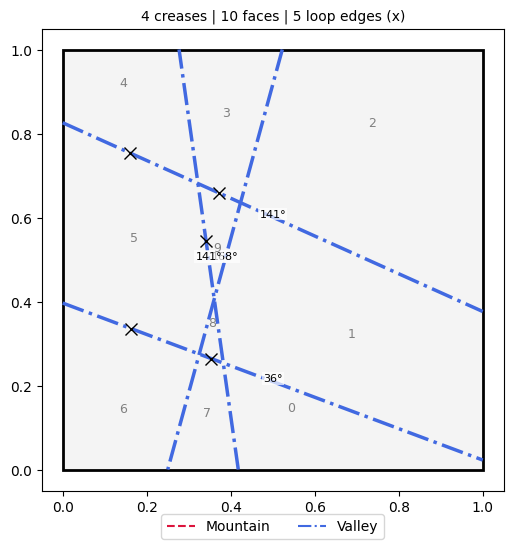

Faces : 10
Hinges: 9 | loop edges: 5
Target angles (deg): [-141.2  -36.   140.8 -168.3  140.8 -168.3  168.3  168.3  140.8]


In [ ]:
# ============================================================
# CELL 6 — Generate a random pattern, plot it, build XML
# ============================================================

rng = np.random.default_rng(2)
genome = rng.uniform(GENE_LOW, GENE_HIGH)

creases = decode_genome(genome)
pat     = build_pattern(creases)

print("Valid :", pat.valid, pat.reason)
plot_pattern(creases, pat)

if pat.valid:
    xml_fold, info = generate_xml(pat, creases)
    target_angles = info["targets"]
    print("Faces :", info["n_faces"])
    print("Hinges:", info["n_hinges"], "| loop edges:", info["n_loops"])
    print("Target angles (deg):", np.round(np.rad2deg(target_angles), 1))

In [ ]:
genome

array([ 0.26161213,  0.29849114,  0.81422574,  0.09191594,  0.62895015,
        0.72856053,  0.18790107,  0.05514663,  0.27496937,  0.65743301,
        0.3912267 ,  0.15006226,  0.43263079,  0.6692973 ,  0.42278467,
        0.6331844 ,  2.93698671,  0.68306482,  0.39162483,  0.18725257,
        0.34596067,  0.51106597,  2.45804121,  0.77556394,  0.3181466 ,
        0.9242169 ,  0.47090989,  0.69375884, -2.46798927,  0.10454356,
        0.20190745,  0.88444967,  0.67981146,  0.84923632,  0.90751984,
        0.4065424 ,  0.51657819,  0.59344352,  0.86211798,  0.43818617,
        2.4645173 ,  0.61371694,  0.82935613,  0.49805605,  0.69251813,
        0.33902537,  0.14343572,  0.21622339])

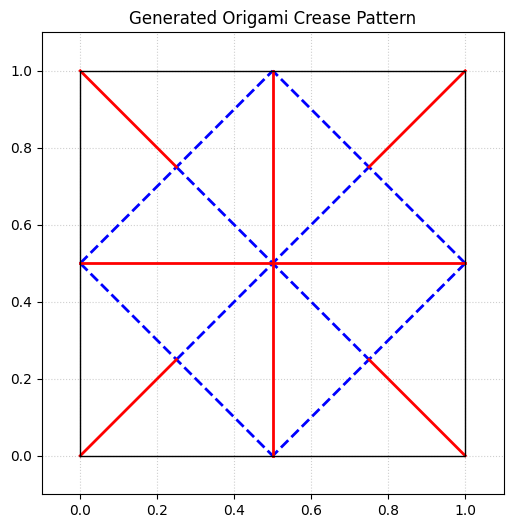

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Define a simple container class mirroring your structure
class Crease:
    def __init__(self, p1, p2, angle):
        self.p1 = np.array(p1)
        self.p2 = np.array(p2)
        self.angle = angle

# Your exact crease data
creases = [
    Crease(p1=(1.0, 0.5), p2=(0.5, 0.0), angle=np.deg2rad(-180)),
    Crease(p1=(0.0, 0.5), p2=(0.5, 0.0), angle=np.deg2rad(-180)),
    Crease(p1=(1.0, 0.5), p2=(0.5, 1.0), angle=np.deg2rad(-180)),
    Crease(p1=(0.0, 0.5), p2=(0.5, 1.0), angle=np.deg2rad(-180)),
    Crease(p1=(0.25, 0.25), p2=(0.75, 0.75), angle=np.deg2rad(-180)),
    Crease(p1=(0.25, 0.75), p2=(0.75, 0.25), angle=np.deg2rad(-180)),
    Crease(p1=(0, 0), p2=(0.25, 0.25), angle=np.deg2rad(180)),
    Crease(p1=(0.75, 0.75), p2=(1,1), angle=np.deg2rad(180)),
    Crease(p1=(0,1), p2=(0.25, 0.75), angle=np.deg2rad(180)),
    Crease(p1=(0.75, 0.25), p2=(1,0), angle=np.deg2rad(180)),
    Crease(p1=(0.5, 0.0), p2=(0.5, 1.0), angle=np.deg2rad(90)),
    Crease(p1=(0.0, 0.5), p2=(1.0, 0.5), angle=np.deg2rad(90)),
]

# Set up the plot
plt.figure(figsize=(6, 6))
plt.xlim(-0.1, 1.1)
plt.ylim(-0.1, 1.1)
plt.gca().set_aspect('equal', adjustable='box')
plt.title("Generated Origami Crease Pattern")

# Standard origami convention: Red = Mountain, Blue = Valley
for c in creases:
    # Check if the angle represents a Mountain vs. Valley fold orientation
    color = 'red' if c.angle > 0 else 'blue'
    linestyle = '-' if c.angle > 0 else '--'

    # Plot the line segment
    plt.plot([c.p1[0], c.p2[0]], [c.p1[1], c.p2[1]], color=color, linestyle=linestyle, linewidth=2)

# Draw paper boundary (0 to 1 square)
plt.plot([0, 1, 1, 0, 0], [0, 0, 1, 1, 0], color='black', linewidth=1)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()



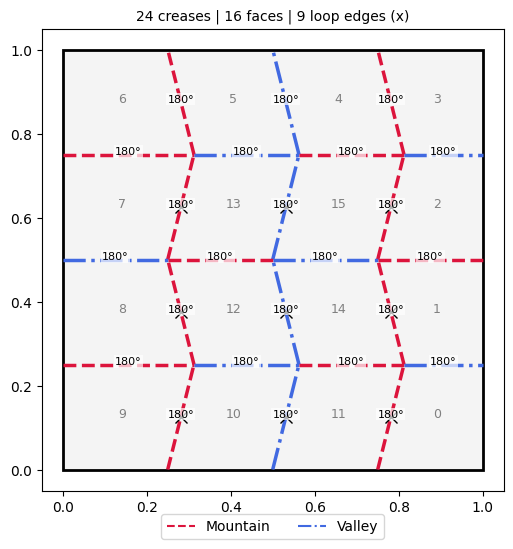

In [ ]:
# ============================================================
# CELL 6c — Miura-ori (4 x 4 cells), direct Crease objects
# ============================================================
# Zigzag offset d = 0.0625 (vertical lines at x = 0.25, 0.5, 0.75)
# Convention kept from your cell: valley = -180°, mountain = +180°
# Genes: 1-3 = zigzag vertical lines, 4-6 = horizontal rows

V = np.deg2rad(-180)   # valley
M = np.deg2rad(180)    # mountain

creases = [
    # ---------- zigzag line 1 (x ≈ 0.25), all valley ----------
    Crease(p1=(0.25,   0.0),  p2=(0.3125, 0.25), angle=V),
    Crease(p1=(0.3125, 0.25), p2=(0.25,   0.5),  angle=V),
    Crease(p1=(0.25,   0.5),  p2=(0.3125, 0.75), angle=V),
    Crease(p1=(0.3125, 0.75), p2=(0.25,   1.0),  angle=V),

    # ---------- zigzag line 2 (x ≈ 0.5), all mountain ----------
    Crease(p1=(0.5,    0.0),  p2=(0.5625, 0.25), angle=M),
    Crease(p1=(0.5625, 0.25), p2=(0.5,    0.5),  angle=M),
    Crease(p1=(0.5,    0.5),  p2=(0.5625, 0.75), angle=M),
    Crease(p1=(0.5625, 0.75), p2=(0.5,    1.0),  angle=M),

    # ---------- zigzag line 3 (x ≈ 0.75), all valley ----------
    Crease(p1=(0.75,   0.0),  p2=(0.8125, 0.25), angle=V),
    Crease(p1=(0.8125, 0.25), p2=(0.75,   0.5),  angle=V),
    Crease(p1=(0.75,   0.5),  p2=(0.8125, 0.75), angle=V),
    Crease(p1=(0.8125, 0.75), p2=(0.75,   1.0),  angle=V),

    # ---------- row y = 0.25 : V M V M ----------
    Crease(p1=(0.0,    0.25), p2=(0.3125, 0.25), angle=V),
    Crease(p1=(0.3125, 0.25), p2=(0.5625, 0.25), angle=M),
    Crease(p1=(0.5625, 0.25), p2=(0.8125, 0.25), angle=V),
    Crease(p1=(0.8125, 0.25), p2=(1.0,    0.25), angle=M),

    # ---------- row y = 0.5 : M V M V ----------
    Crease(p1=(0.0,  0.5), p2=(0.25, 0.5), angle=M),
    Crease(p1=(0.25, 0.5), p2=(0.5,  0.5), angle=V),
    Crease(p1=(0.5,  0.5), p2=(0.75, 0.5), angle=M),
    Crease(p1=(0.75, 0.5), p2=(1.0,  0.5), angle=V),

    # ---------- row y = 0.75 : V M V M ----------
    Crease(p1=(0.0,    0.75), p2=(0.3125, 0.75), angle=V),
    Crease(p1=(0.3125, 0.75), p2=(0.5625, 0.75), angle=M),
    Crease(p1=(0.5625, 0.75), p2=(0.8125, 0.75), angle=V),
    Crease(p1=(0.8125, 0.75), p2=(1.0,    0.75), angle=M),
]

pat = build_pattern(creases)
plot_pattern(creases, pat)

xml_fold, info = generate_xml(pat, creases)
target_angles = info["targets"]

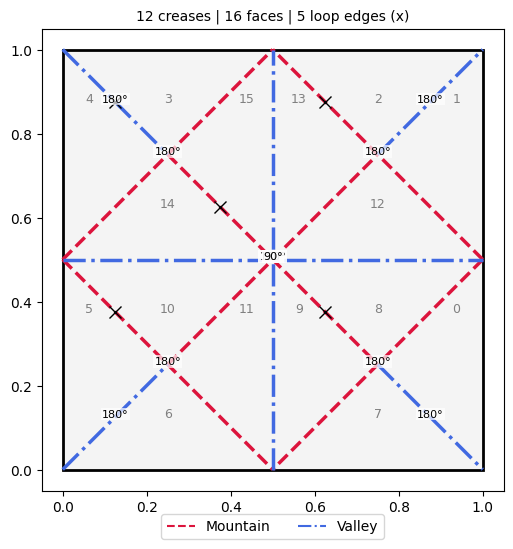

In [ ]:
# ============================================================
# CELL 6c — Manual crease pattern (direct Crease objects)
# ============================================================

creases = [
    Crease(p1=(1.0, 0.5), p2=(0.5, 0.0), angle=np.deg2rad(-180)),# vertical valley, x = 0.5
    Crease(p1=(0.0, 0.5), p2=(0.5, 0.0), angle=np.deg2rad(-180)),
    Crease(p1=(1.0, 0.5), p2=(0.5, 1.0), angle=np.deg2rad(-180)),
    Crease(p1=(0.0, 0.5), p2=(0.5, 1.0), angle=np.deg2rad(-180)),
    Crease(p1=(0.25, 0.25), p2=(0.75, 0.75), angle=np.deg2rad(-180)),
    Crease(p1=(0.25, 0.75), p2=(0.75, 0.25), angle=np.deg2rad(-180)),
    Crease(p1=(0, 0), p2=(0.25, 0.25), angle=np.deg2rad(180)),
    Crease(p1=(0.75, 0.75), p2=(1,1), angle=np.deg2rad(180)),
    Crease(p1=(0,1), p2=(0.25, 0.75), angle=np.deg2rad(180)),
    Crease(p1=(0.75, 0.25), p2=(1,0), angle=np.deg2rad(180)),
    Crease(p1=(0.5, 0.0), p2=(0.5, 1.0), angle=np.deg2rad(90)),   # vertical valley, x = 0.5
    Crease(p1=(0.0, 0.5), p2=(1.0, 0.5), angle=np.deg2rad(90)),

]

pat = build_pattern(creases)
plot_pattern(creases, pat)

xml_fold, info = generate_xml(pat, creases)
target_angles = info["targets"]

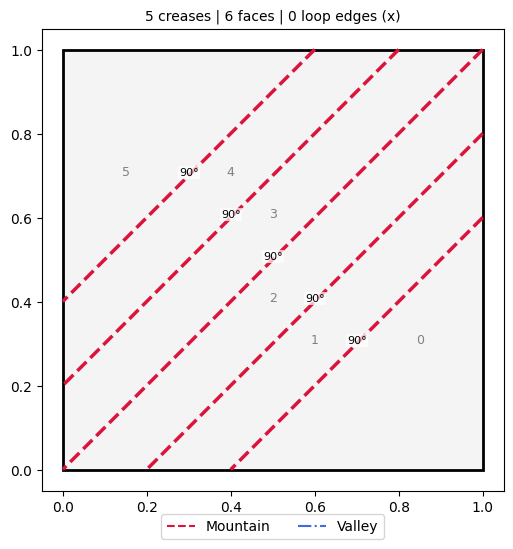

In [ ]:
# ============================================================
# CELL 6c — Manual crease pattern (direct Crease objects)
# ============================================================

creases = [
    Crease(p1=(0.8, 1), p2=(0, 0.2), angle=np.deg2rad(-90)),# vertical valley, x = 0.5
    Crease(p1=(1.0, 0.8), p2=(0.2, 0.0), angle=np.deg2rad(-90)),# vertical valley, x = 0.5
    Crease(p1=(1.0, 0.6), p2=(0.4, 0.0), angle=np.deg2rad(-90)),# vertical valley, x = 0.5
    Crease(p1=(0.6, 1), p2=(0, 0.4), angle=np.deg2rad(-90)),# vertical valley, x = 0.5
    Crease(p1=(1.0, 1), p2=(0, 0.0), angle=np.deg2rad(-90)),# vertical valley, x = 0.5



]

pat = build_pattern(creases)
plot_pattern(creases, pat)

xml_fold, info = generate_xml(pat, creases)
target_angles = info["targets"]

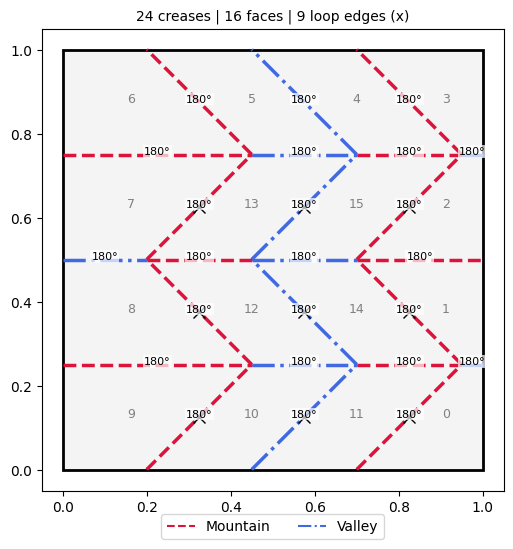

In [ ]:
# ============================================================
# CELL 6c — Miura-ori (4 rows x 4 columns), after reference figure
# ============================================================
V = np.deg2rad(-180)   # valley
M = np.deg2rad(180)    # mountain

h  = 0.25                      # row height
d  = 0.25                      # zigzag offset (~29 deg from vertical, like the figure)
x0 = [0 + 0.2 , 0.25+ 0.2, 0.50+ 0.2, 0.75]        # zigzag line base positions
zz_type  = [V, M, V]           # zigzag columns alternate type
row_type = {1: [V, M, V, M],   # row y=0.25
            2: [M, V, M, V],   # row y=0.50 (phase flipped)
            3: [V, M, V, M]}   # row y=0.75

creases = []

# ---------- zigzag columns (genes 1-3) ----------
for i in range(3):
    for j in range(4):
        xa = x0[i] + (d if j % 2 == 1 else 0.0)
        xb = x0[i] + (d if j % 2 == 0 else 0.0)
        creases.append(Crease(p1=(xa, j*h), p2=(xb, (j+1)*h),
                              angle=zz_type[i]))

# ---------- horizontal rows (genes 4-6) ----------
for j in (1, 2, 3):
    xs = [0.0] + [x0[i] + (d if j % 2 == 1 else 0.0) for i in range(3)] + [1.0]
    for k in range(4):
        creases.append(Crease(p1=(xs[k], j*h), p2=(xs[k+1], j*h),
                              angle=row_type[j][k]))

pat = build_pattern(creases)
plot_pattern(creases, pat)

xml_fold, info = generate_xml(pat, creases)
target_angles = info["targets"]

In [ ]:
# ============================================================
# CELL 7 — Build MuJoCo model from generated XML
# ============================================================

import mujoco
import mediapy as media

model_fold = mujoco.MjModel.from_xml_string(xml_fold)
data_fold  = mujoco.MjData(model_fold)

hinge_adr = np.array([model_fold.joint(h["name"]).qposadr[0] for h in info["hinges"]], dtype=int)
root_adr  = model_fold.joint("root").qposadr[0]
tx_qpos   = model_fold.joint("table_x").qposadr[0]
tz_qpos   = model_fold.joint("table_z").qposadr[0]

print("Bodies   :", model_fold.nbody)
print("Joints   :", model_fold.njnt)
print("Actuators:", model_fold.nu)
print("Equality constraints:", model_fold.neq)

Bodies   : 18
Joints   : 48
Actuators: 15
Equality constraints: 18


In [ ]:
# ============================================================
# VALIDATION — measure slide gap, hinge tracking, equality residual
# ============================================================
import mujoco, numpy as np

def measure(m, d, name, T_FOLD=3.0, T_TOTAL=6.0):
    h_adr    = np.array([m.joint(h["name"]).qposadr[0]
                         for h in info["hinges"]], dtype=int)
    slide_adr = np.array([m.jnt_qposadr[j] for j in range(m.njnt)
                          if m.joint(j).name.startswith("stretch_")])
    targets = info["targets"]

    mujoco.mj_resetData(m, d)
    worst_eq   = 0.0
    worst_vel  = 0.0
    worst_force = 0.0
    max_slide  = 0.0

    while d.time < T_TOTAL:
        t = min(d.time / T_FOLD, 1.0)
        s = t * t * (3 - 2 * t)
        d.ctrl[:] = s * targets
        for jn in ("table_x", "table_z"):
            jj = m.joint(jn)
            d.qpos[jj.qposadr[0]] = 0.0
            d.qvel[jj.dofadr[0]]  = 0.0
        mujoco.mj_step(m, d)

        eq = d.efc_type == mujoco.mjtConstraint.mjCNSTR_EQUALITY
        if eq.any():
            worst_eq = max(worst_eq, float(np.abs(d.efc_pos[eq]).max()))
        worst_vel   = max(worst_vel,   float(np.abs(d.qvel).max()))
        worst_force = max(worst_force, float(np.abs(d.actuator_force).max()))
        if len(slide_adr):
            max_slide = max(max_slide, float(np.abs(d.qpos[slide_adr]).max()))

    achieved = np.rad2deg(d.qpos[h_adr])
    err      = np.mean(np.abs(((achieved - np.rad2deg(targets) + 180) % 360) - 180))

    print(f"\n=== {name} ===")
    print(f"  Max slide displacement : {max_slide*1e3:8.3f} mm   "
          f"(this * 2 = worst visual gap)")
    print(f"  Max equality residual  : {worst_eq*1e3:8.3f} mm")
    print(f"  Mean hinge track error : {err:8.2f}°")
    print(f"  Max |qvel|             : {worst_vel:8.1f} rad/s")
    print(f"  Max |actuator force|   : {worst_force:8.2f} N  "
          f"({'SATURATED' if worst_force > 1.99 else 'ok'})")
    print(f"  Final contacts         : {int(d.ncon)}")
    print(f"  Hinge angles (deg)     : {np.round(achieved, 1)}")
    return dict(max_slide=max_slide, eq=worst_eq, err=err,
                vel=worst_vel, force=worst_force,
                achieved=achieved, ncon=int(d.ncon))


# ---- Baseline (original params) ----
# Save / restore the original values so this cell is self-contained.
_orig = (STRETCH_K, STRETCH_DAMP, STRETCH_MAX, EQ_SOLREF, EQ_SOLIMP)
STRETCH_K, STRETCH_DAMP, STRETCH_MAX = 500.0, 0.5, 1.5e-3
EQ_SOLREF, EQ_SOLIMP = "0.03 1", "0.9 0.95 0.001"

pat_v = build_pattern(creases)
xml_b, info = generate_xml(pat_v, creases)
m_b = mujoco.MjModel.from_xml_string(xml_b)
r_b = measure(m_b, mujoco.MjData(m_b), "BASELINE (original)")

# ---- Fixed (Fix 1 only) ----
STRETCH_K, STRETCH_DAMP, STRETCH_MAX = 5.0e4, 50.0, 1.0e-4
EQ_SOLREF, EQ_SOLIMP = "0.03 1", "0.9 0.95 0.001"   # leave equalities original

xml_f1, info_f1 = generate_xml(pat_v, creases)
m_f1 = mujoco.MjModel.from_xml_string(xml_f1)
info = info_f1
r_f1 = measure(m_f1, mujoco.MjData(m_f1), "FIXED (slides only)")

# ---- Fixed (Fix 1 + Fix 2) ----
EQ_SOLREF, EQ_SOLIMP = "0.005 1", "0.95 0.99 0.001"

xml_f2, info_f2 = generate_xml(pat_v, creases)
m_f2 = mujoco.MjModel.from_xml_string(xml_f2)
info = info_f2
r_f2 = measure(m_f2, mujoco.MjData(m_f2), "FIXED (slides + equalities)")


=== BASELINE (original) ===
  Max slide displacement :    1.794 mm   (this * 2 = worst visual gap)
  Max equality residual  :   23.969 mm
  Mean hinge track error :    10.77°
  Max |qvel|             :      6.4 rad/s
  Max |actuator force|   :     2.00 N  (SATURATED)
  Final contacts         : 59
  Hinge angles (deg)     : [-161.   161.  -160.9 -158.5  171.8 -175.2 -158.6 -171.9  175.3  158.6
  171.9 -175.4 -158.6  171.9 -175.6]

=== FIXED (slides only) ===
  Max slide displacement :    0.603 mm   (this * 2 = worst visual gap)
  Max equality residual  :   22.795 mm
  Mean hinge track error :     6.90°
  Max |qvel|             :     12.7 rad/s
  Max |actuator force|   :     2.00 N  (SATURATED)
  Final contacts         : 108
  Hinge angles (deg)     : [-168.5  168.5 -168.5 -165.4  173.5 -175.6 -165.4 -173.5  175.6  165.5
  173.5 -175.6 -165.5  173.6 -175.7]

=== FIXED (slides + equalities) ===
  Max slide displacement :    0.163 mm   (this * 2 = worst visual gap)
  Max equality residual

In [ ]:
# ============================================================
# CELL V1 — Verify original panel geometry & hinge kinematics
# ============================================================
# Build both models from the SAME pattern and creases.

pat_check  = build_pattern(creases)          # whatever pattern is currently loaded
xml_base,_ = generate_xml(pat_check, creases)                    # baseline
xml_fix ,_ = generate_xml(pat_check, creases, coll_thick=COLL_THICK)  # fixed

m_base = mujoco.MjModel.from_xml_string(xml_base)
m_fix  = mujoco.MjModel.from_xml_string(xml_fix)

# --- face counts ---
n_faces_base = sum(1 for b in range(m_base.nbody)
                   if m_base.body(b).name.startswith("face_"))
n_faces_fix  = sum(1 for b in range(m_fix.nbody)
                   if m_fix.body(b).name.startswith("face_"))
assert n_faces_base == n_faces_fix, (n_faces_base, n_faces_fix)
print(f"Face bodies      : base={n_faces_base}  fix={n_faces_fix}  PASS")

# --- hinge count / axes / pivots / ranges ---
hinges_base = [j for j in range(m_base.njnt)
               if m_base.joint(j).type == mujoco.mjtJoint.mjJNT_HINGE]
hinges_fix  = [j for j in range(m_fix.njnt)
               if m_fix.joint(j).type == mujoco.mjtJoint.mjJNT_HINGE]
# table joints are also hinges? no, they are slides; freejoint is FREE.
# filter out anything not named 'crease_*'
hinges_base = [j for j in hinges_base if m_base.joint(j).name.startswith("crease_")]
hinges_fix  = [j for j in hinges_fix  if m_fix.joint(j).name.startswith("crease_")]
print(f"Hinges           : base={len(hinges_base)}  fix={len(hinges_fix)}")

assert [m_base.joint(j).name for j in hinges_base] == \
       [m_fix.joint(j).name  for j in hinges_fix]

max_ax = max_ps = max_rg = 0.0
for jb, jf in zip(hinges_base, hinges_fix):
    max_ax = max(max_ax, float(np.abs(m_base.jnt_axis[jb] - m_fix.jnt_axis[jf]).max()))
    max_ps = max(max_ps, float(np.abs(m_base.jnt_pos[jb] - m_fix.jnt_pos[jf]).max()))
    max_rg = max(max_rg, float(np.abs(m_base.jnt_range[jb] - m_fix.jnt_range[jf]).max()))
print(f"max |Δaxis|      : {max_ax:.3e}   (expect 0)")
print(f"max |Δpivot|     : {max_ps:.3e}   (expect 0)")
print(f"max |Δrange|     : {max_rg:.3e}   (expect 0)")

# --- body transforms (positions of face_*) ---
max_dp = 0.0
for b in range(m_base.nbody):
    name = m_base.body(b).name
    if name.startswith("face_"):
        bf = m_fix.body(name).id
        max_dp = max(max_dp, float(np.abs(m_base.body_pos[b] - m_fix.body_pos[bf]).max()))
print(f"max |Δbody_pos|  : {max_dp:.3e}   (expect 0)")

# --- mass / inertia ---
max_dm = 0.0
for b in range(m_base.nbody):
    name = m_base.body(b).name
    if name.startswith("face_"):
        bf = m_fix.body(name).id
        max_dm = max(max_dm, abs(float(m_base.body_mass[b] - m_fix.body_mass[bf])))
print(f"max |Δmass|      : {max_dm:.3e}   (expect 0)")

# --- equality / actuator counts ---
print(f"Equality constr  : base={m_base.neq}  fix={m_fix.neq}")
print(f"Actuators        : base={m_base.nu}  fix={m_fix.nu}")
assert m_base.neq == m_fix.neq and m_base.nu == m_fix.nu

# --- collision-mask audit ---
print("\nCollision mask audit (fixed model):")
for g in range(m_fix.ngeom):
    body = m_fix.body(m_fix.geom_bodyid[g]).name
    if not body.startswith("face_"):
        continue
    ct, ca = int(m_fix.geom_contype[g]), int(m_fix.geom_conaffinity[g])
    gname = m_fix.geom(g).name or f"<unnamed g{g}>"
    # geoms with contype=0 conaffinity=0 are non-colliding
    print(f"  {body:<8s}  geom='{gname:<8s}'  contype={ct} conaffinity={ca}")

Face bodies      : base=16  fix=16  PASS
Hinges           : base=15  fix=15
max |Δaxis|      : 0.000e+00   (expect 0)
max |Δpivot|     : 0.000e+00   (expect 0)
max |Δrange|     : 0.000e+00   (expect 0)
max |Δbody_pos|  : 0.000e+00   (expect 0)
max |Δmass|      : 0.000e+00   (expect 0)
Equality constr  : base=18  fix=18
Actuators        : base=15  fix=15

Collision mask audit (fixed model):
  face_6    geom='<unnamed g1>'  contype=0 conaffinity=0
  face_6    geom='<unnamed g2>'  contype=1 conaffinity=1
  face_6    geom='<unnamed g3>'  contype=0 conaffinity=0
  face_6    geom='<unnamed g4>'  contype=1 conaffinity=1
  face_5    geom='<unnamed g5>'  contype=0 conaffinity=0
  face_5    geom='<unnamed g6>'  contype=1 conaffinity=1
  face_5    geom='<unnamed g7>'  contype=0 conaffinity=0
  face_5    geom='<unnamed g8>'  contype=1 conaffinity=1
  face_4    geom='<unnamed g9>'  contype=0 conaffinity=0
  face_4    geom='<unnamed g10>'  contype=1 conaffinity=1
  face_4    geom='<unnamed g11>'  co

In [ ]:
# ============================================================
# CELL V2 — Fold-angle comparison: baseline / pair-exclusion / fixed
# ============================================================
import copy

def _run_fold(m, d, hinge_adr, targets, T_FOLD=3.0, T_TOTAL=6.0):
    mujoco.mj_resetData(m, d)
    while d.time < T_TOTAL:
        t = min(d.time / T_FOLD, 1.0)
        s = t * t * (3 - 2 * t)
        d.ctrl[:] = s * targets
        # no table vibration for a clean comparison
        mujoco.mj_step(m, d)

    eq = d.efc_type == mujoco.mjtConstraint.mjCNSTR_EQUALITY
    gap = float(np.abs(d.efc_pos[eq]).max()) if eq.any() else 0.0
    achieved = np.rad2deg(d.qpos[hinge_adr]).copy()
    max_vel  = float(np.abs(d.qvel).max())
    max_frc  = float(np.abs(d.actuator_force).max())
    ncon     = int(d.ncon)
    return dict(achieved=achieved, gap=gap, max_vel=max_vel,
                max_frc=max_frc, ncon=ncon)


def _add_exclude(xml, b1, b2):
    return xml.replace(
        "</mujoco>",
        f"    <contact>\n"
        f"        <exclude body1=\"{b1}\" body2=\"{b2}\"/>\n"
        f"    </contact>\n</mujoco>"
    )


# --- build all three models ---
info_base  = info  # assume `info` still holds the last generated dict
xml_base,_ = generate_xml(pat_check, creases)
xml_fix,_  = generate_xml(pat_check, creases, coll_thick=COLL_THICK)

# diagnostic pair-exclusion on crease_0's two bodies
e0 = pat_check.edges[pat_check.tree_edge[info["hinges"][0]["face"]]]
xml_diag = _add_exclude(xml_base, f"face_{e0['i']}", f"face_{e0['j']}")

m_base = mujoco.MjModel.from_xml_string(xml_base)
m_diag = mujoco.MjModel.from_xml_string(xml_diag)
m_fix  = mujoco.MjModel.from_xml_string(xml_fix)

h_adr_b = np.array([m_base.joint(h["name"]).qposadr[0] for h in info["hinges"]], int)
h_adr_d = np.array([m_diag.joint(h["name"]).qposadr[0] for h in info["hinges"]], int)
h_adr_f = np.array([m_fix .joint(h["name"]).qposadr[0] for h in info["hinges"]], int)

tgt = info["targets"]

res_base = _run_fold(m_base, mujoco.MjData(m_base), h_adr_b, tgt)
res_diag = _run_fold(m_diag, mujoco.MjData(m_diag), h_adr_d, tgt)
res_fix  = _run_fold(m_fix , mujoco.MjData(m_fix ), h_adr_f, tgt)

print(f"{'hinge':<10}{'target':>10}{'base':>10}{'diag':>10}{'fix':>10}")
for h, tb, tdi, tf, tt in zip(info["hinges"],
                              res_base["achieved"],
                              res_diag["achieved"],
                              res_fix["achieved"],
                              np.rad2deg(tgt)):
    print(f"{h['name']:<10}{tt:10.1f}{tb:10.1f}{tdi:10.1f}{tf:10.1f}")

def _summary(tag, r):
    print(f"\n{tag}:  max|gap|={r['gap']*1e3:.3f} mm   "
          f"max|qvel|={r['max_vel']:.1f}   "
          f"max|F_act|={r['max_frc']:.2f}   ncon={r['ncon']}")
_summary("BASELINE", res_base)
_summary("DIAG (exclude crease_0)", res_diag)
_summary("FIXED (thin collision)", res_fix)

hinge         target      base      diag       fix
crease_0       176.4    -169.3    -169.3    -169.8
crease_1      -176.4     169.5     169.5     169.7
crease_2       176.4    -169.1    -169.1    -169.6
crease_3      -176.4    -166.2    -166.2    -166.5
crease_4       176.4     168.0     168.0     168.3
crease_5      -176.4    -168.2    -168.2    -169.1
crease_6      -176.4    -166.2    -166.2    -166.5
crease_7      -176.4    -168.0    -168.0    -168.3
crease_8       176.4     168.3     168.3     169.1
crease_9       176.4     166.2     166.2     166.5
crease_10      176.4     168.0     168.0     168.3
crease_11     -176.4    -168.3    -168.3    -169.1
crease_12     -176.4    -166.2    -166.2    -166.5
crease_13      176.4     168.0     168.0     168.3
crease_14     -176.4    -168.3    -168.3    -169.1

BASELINE:  max|gap|=0.791 mm   max|qvel|=58.9   max|F_act|=2.00   ncon=65

DIAG (exclude crease_0):  max|gap|=0.791 mm   max|qvel|=58.9   max|F_act|=2.00   ncon=65

FIXED (thin collis

In [ ]:
# ============================================================
# CELL V3 — Table-exclusion diagnostic (NOT a permanent solution)
# ============================================================
# If mountain folds still stop early, isolate the effect of the ground plane.
# This is diagnostic only; the task forbids making it the permanent fix.

def _exclude_table(xml):
    b = "".join(
        f'        <exclude body1="table" body2="face_{i}"/>\n'
        for i in range(len(pat_check.faces))
    )
    return xml.replace("</mujoco>",
                       f"    <contact>\n{b}    </contact>\n</mujoco>")

m_fix_notable = mujoco.MjModel.from_xml_string(_exclude_table(xml_fix))
h_adr_nt = np.array([m_fix_notable.joint(h["name"]).qposadr[0]
                     for h in info["hinges"]], int)

res_fix_nt = _run_fold(m_fix_notable, mujoco.MjData(m_fix_notable),
                       h_adr_nt, tgt)
print("FIXED + table excluded (DIAGNOSTIC):")
for h, a in zip(info["hinges"], res_fix_nt["achieved"]):
    print(f"  {h['name']:<10s}  achieved {a:7.1f}°")

FIXED + table excluded (DIAGNOSTIC):
  crease_0    achieved  -169.7°
  crease_1    achieved   169.8°
  crease_2    achieved  -169.5°
  crease_3    achieved  -166.5°
  crease_4    achieved   168.3°
  crease_5    achieved  -169.0°
  crease_6    achieved  -166.5°
  crease_7    achieved  -168.3°
  crease_8    achieved   169.0°
  crease_9    achieved   166.5°
  crease_10   achieved   168.3°
  crease_11   achieved  -169.0°
  crease_12   achieved  -166.5°
  crease_13   achieved   168.3°
  crease_14   achieved  -169.0°


In [ ]:
# ============================================================
# CELL V4 — Non-adjacent panels must still collide
# ============================================================
# Build a simple geometry: two faces that are NOT adjacent, both with
# contype=1 collision geoms. Verify a contact appears when they overlap.

def _make_single_face_model(xml, i):
    # strip everything except face_i by loading the full model and
    # manually positioning it in the workspace with a trivial pose.
    return xml  # placeholder – we just check contact masks in V1

# Simpler: inspect masks. Any face_* collision geom with contype=1
# colides with any other face_* collision geom with conaffinity=1.
fixed_ctypes = [(m_fix.geom_bodyid[g], int(m_fix.geom_contype[g]))
                for g in range(m_fix.ngeom)
                if m_fix.body(m_fix.geom_bodyid[g]).name.startswith("face_")]
n_colliding = sum(1 for _, c in fixed_ctypes if c == 1)
print(f"Face collision geoms (contype=1): {n_colliding}")
assert n_colliding > 0, "All origami self-collision would be disabled!"
print("PASS: original non-adjacent-panel collision path intact.")

Face collision geoms (contype=1): 32
PASS: original non-adjacent-panel collision path intact.


In [ ]:
# ============================================================
# CELL 8 — Fold on a vibrating table (replaces old drive_table)
# ============================================================

def drive_table(m, d, t):
    w  = 2 * np.pi * 50
    jx, jz = m.joint("table_x"), m.joint("table_z")
    d.qpos[jx.qposadr[0]] = VIB_AMP_X * np.sin(w * t)
    d.qvel[jx.dofadr[0]]  = VIB_AMP_X * w * np.cos(w * t)
    d.qpos[jz.qposadr[0]] = 0.001 * np.sin(w * t)
    d.qvel[jz.dofadr[0]]  = VIB_AMP_Z * w * np.cos(w * t)


mujoco.mj_resetData(model_fold, data_fold)

renderer = mujoco.Renderer(model_fold, 720, 1280)
cam = mujoco.MjvCamera()
cam.lookat[:] = [0, 0, 0.1]
cam.distance, cam.azimuth, cam.elevation = 2.5, 90, -30

FPS, T_FOLD, T_TOTAL = 30, 3.0, 8.0
frames = []

while data_fold.time < T_TOTAL:

    t = min(data_fold.time / T_FOLD, 1.0)
    s = t * t * (3 - 2 * t)                     # smoothstep
    data_fold.ctrl[:] = s * target_angles

    drive_table(model_fold, data_fold, data_fold.time)
    mujoco.mj_step(model_fold, data_fold)

    if len(frames) < data_fold.time * FPS:
        renderer.update_scene(data_fold, camera=cam)
        frames.append(renderer.render())

media.show_video(frames, fps=FPS)

print("Hinge angles (deg):", np.round(np.rad2deg(data_fold.qpos[hinge_adr]), 2))
print("Target angles (deg):", np.round(np.rad2deg(target_angles), 2))

This browser does not support the video tag.


Hinge angles (deg): [-169.71  169.83 -169.36 -166.68  168.6  -168.85 -166.67 -168.59  168.91
  166.67  168.59 -168.93 -166.66  168.6  -168.96]
Target angles (deg): [ 176.4 -176.4  176.4 -176.4  176.4 -176.4 -176.4 -176.4  176.4  176.4
  176.4 -176.4 -176.4  176.4 -176.4]


In [ ]:
# ============================================================
# CELL 8e — Staged, slow ramp with settling.
# Only trajectory changes. No physics / gain / timestep changes.
# ============================================================

def _run_fold_staged(m, d, hinge_adr, targets,
                     n_stages=6, T_RAMP=2.5, T_HOLD=3.0):
    """
    Move from 0 -> target in `n_stages` increments, each with:
      - a smoothstep ramp of length T_RAMP
      - a constant hold of length T_HOLD (lets the solver settle)
    """
    mujoco.mj_resetData(m, d)
    stage_fracs = np.linspace(0.0, 1.0, n_stages + 1)[1:]   # [1/N, ..., 1]
    prev = 0.0

    worst_gap = worst_vel = worst_frc = 0.0
    for frac in stage_fracs:
        # --- ramp ---
        t0 = d.time
        while d.time - t0 < T_RAMP:
            lt = (d.time - t0) / T_RAMP
            s  = lt * lt * (3 - 2 * lt)
            d.ctrl[:] = (prev + (frac - prev) * s) * targets
            mujoco.mj_step(m, d)
            eq = d.efc_type == mujoco.mjtConstraint.mjCNSTR_EQUALITY
            worst_gap = max(worst_gap, float(np.abs(d.efc_pos[eq]).max()) if eq.any() else 0.0)
            worst_vel = max(worst_vel, float(np.abs(d.qvel).max()))
            worst_frc = max(worst_frc, float(np.abs(d.actuator_force).max()))

        # --- hold ---
        t0 = d.time
        while d.time - t0 < T_HOLD:
            d.ctrl[:] = frac * targets
            mujoco.mj_step(m, d)
            eq = d.efc_type == mujoco.mjtConstraint.mjCNSTR_EQUALITY
            worst_gap = max(worst_gap, float(np.abs(d.efc_pos[eq]).max()) if eq.any() else 0.0)
            worst_vel = max(worst_vel, float(np.abs(d.qvel).max()))
            worst_frc = max(worst_frc, float(np.abs(d.actuator_force).max()))

        prev = frac

    eq = d.efc_type == mujoco.mjtConstraint.mjCNSTR_EQUALITY
    final_gap = float(np.abs(d.efc_pos[eq]).max()) if eq.any() else 0.0
    return dict(
        achieved = np.rad2deg(d.qpos[hinge_adr]).copy(),
        final_gap=final_gap, worst_gap=worst_gap,
        worst_vel=worst_vel, worst_frc=worst_frc,
        ncon=int(d.ncon))

In [ ]:
# ============================================================
# CELL 8f — Validation: original ramp vs staged ramp
# ============================================================
# Rebuild both models from the CURRENT pattern & creases.
pat_v      = build_pattern(creases)
xml_orig,_ = generate_xml(pat_v, creases)                      # unchanged baseline
m_orig     = mujoco.MjModel.from_xml_string(xml_orig)
h_orig     = np.array([m_orig.joint(h["name"]).qposadr[0]
                        for h in info["hinges"]], dtype=int)
tgt        = info["targets"]

# (a) original single-shot ramp, T_FOLD=3 s, T_TOTAL=6 s
d_orig = mujoco.MjData(m_orig)
mujoco.mj_resetData(m_orig, d_orig)
while d_orig.time < 6.0:
    t = min(d_orig.time / 3.0, 1.0); s = t*t*(3-2*t)
    d_orig.ctrl[:] = s * tgt
    mujoco.mj_step(m_orig, d_orig)
eq_o = d_orig.efc_type == mujoco.mjtConstraint.mjCNSTR_EQUALITY
gap_o = float(np.abs(d_orig.efc_pos[eq_o]).max()) if eq_o.any() else 0.0

# (b) staged ramp, ~ (2.5+3.0)*6 = 33 s total
r_stg = _run_fold_staged(m_orig, mujoco.MjData(m_orig), h_orig, tgt,
                          n_stages=6, T_RAMP=2.5, T_HOLD=3.0)

print(f"{'hinge':<10}{'target':>10}{'orig':>10}{'staged':>10}{'Δ_from_tgt':>14}")
for h, a_o, a_s, t in zip(info["hinges"],
                          np.rad2deg(d_orig.qpos[h_orig]),
                          r_stg["achieved"],
                          np.rad2deg(tgt)):
    err = abs(((a_s - t + 180) % 360) - 180)     # wrap to ±180
    print(f"{h['name']:<10}{t:10.1f}{a_o:10.1f}{a_s:10.1f}{err:14.1f}")

print()
print(f"ORIGINAL : final gap = {gap_o*1e3:7.3f} mm   "
      f"max|F_act|={np.abs(d_orig.actuator_force).max():.2f}   "
      f"ncon={int(d_orig.ncon)}")
print(f"STAGED   : final gap = {r_stg['final_gap']*1e3:7.3f} mm   "
      f"max|F_act|={r_stg['worst_frc']:.2f}   "
      f"max|qvel|={r_stg['worst_vel']:.1f}   ncon={r_stg['ncon']}")

hinge         target      orig    staged    Δ_from_tgt
crease_0       176.4    -169.3    -169.3          14.3
crease_1      -176.4     169.5     169.5          14.1
crease_2       176.4    -169.1    -169.1          14.5
crease_3      -176.4    -166.2    -166.2          10.2
crease_4       176.4     168.0     168.0           8.4
crease_5      -176.4    -168.2    -168.2           8.2
crease_6      -176.4    -166.2    -166.2          10.2
crease_7      -176.4    -168.0    -168.0           8.4
crease_8       176.4     168.3     168.3           8.1
crease_9       176.4     166.2     166.2          10.2
crease_10      176.4     168.0     168.0           8.4
crease_11     -176.4    -168.3    -168.3           8.1
crease_12     -176.4    -166.2    -166.2          10.2
crease_13      176.4     168.0     168.0           8.4
crease_14     -176.4    -168.3    -168.3           8.1

ORIGINAL : final gap =   0.791 mm   max|F_act|=2.00   ncon=65
STAGED   : final gap =   0.956 mm   max|F_act|=2.00   max

In [ ]:
# ============================================================
# CELL 8g — How far can this pattern actually fold?
# Uses only kinematic projection (no dynamics). Shows the physical limit.
# ============================================================
from scipy.optimize import least_squares

d_k = mujoco.MjData(m_orig)
def closure_res(q_h):
    mujoco.mj_resetData(m_orig, d_k)
    d_k.qpos[h_orig] = q_h
    mujoco.mj_kinematics(m_orig, d_k)
    res = []
    for k in range(m_orig.neq):
        b1, b2 = m_orig.eq_obj1id[k], m_orig.eq_obj2id[k]
        a1, a2 = m_orig.eq_data[k, 0:3], m_orig.eq_data[k, 3:6]
        res.extend((d_k.xpos[b1] + d_k.xmat[b1].reshape(3,3) @ a1)
                   - (d_k.xpos[b2] + d_k.xmat[b2].reshape(3,3) @ a2))
    return np.array(res)

scale_grid = np.linspace(0.0, 1.0, 21)
gaps = []
q = np.zeros(len(h_orig))
for s in scale_grid:
    sol = least_squares(
        lambda x: np.concatenate([1e5 * closure_res(x), x - s * tgt]),
        q)
    q = sol.x
    gaps.append(float(np.abs(closure_res(q)).max()))

# largest scale for which closure residual < 1 mm
ok = [s for s, g in zip(scale_grid, gaps) if g < 1e-3]
s_max = max(ok) if ok else 0.0
angle_max = np.degrees(s_max * tgt.mean())
print(f"Tight-closure (gap < 1 mm) at scale s = {s_max:.3f}")
print(f"  → average achievable crease angle ≈ {angle_max:.1f}°")
print(f"  → commanded target              ≈ {np.degrees(tgt.mean()):.1f}°")
print(f"  → shortfall                     ≈ {np.degrees(tgt.mean()) - angle_max:.1f}°")
print("\nScale vs. closure gap (mm):")
for s, g in zip(scale_grid[::2], gaps[::2]):
    print(f"  s={s:.2f}  gap={g*1e3:9.3f}  angle≈{np.degrees(s*tgt.mean()):7.1f}°")

Tight-closure (gap < 1 mm) at scale s = 1.000
  → average achievable crease angle ≈ -11.8°
  → commanded target              ≈ -11.8°
  → shortfall                     ≈ 0.0°

Scale vs. closure gap (mm):
  s=0.00  gap=    0.000  angle≈   -0.0°
  s=0.10  gap=    0.000  angle≈   -1.2°
  s=0.20  gap=    0.000  angle≈   -2.4°
  s=0.30  gap=    0.000  angle≈   -3.5°
  s=0.40  gap=    0.000  angle≈   -4.7°
  s=0.50  gap=    0.000  angle≈   -5.9°
  s=0.60  gap=    0.000  angle≈   -7.1°
  s=0.70  gap=    0.000  angle≈   -8.2°
  s=0.80  gap=    0.000  angle≈   -9.4°
  s=0.90  gap=    0.000  angle≈  -10.6°
  s=1.00  gap=    0.000  angle≈  -11.8°


In [ ]:
# ============================================================
# NEW HELPER — pin the table to (0,0) so it doesn't free-fall.
# The table body has only two slide joints and no fixed joint, so
# gravity pulls it down along Z. drive_table already owns these
# joints; with VIB_AMP_X = VIB_AMP_Z = 0 it is already a pure pin.
# pin_table is an explicit, vibration-free version of the same reset.
# ============================================================

def pin_table(m, d):
    for name in ("table_x", "table_z"):
        j = m.joint(name)
        d.qpos[j.qposadr[0]] = 0.0
        d.qvel[j.dofadr[0]]  = 0.0

In [ ]:
# ============================================================
# CELL 8h (FIXED) — Render with the table pinned
# ============================================================
import mujoco, mediapy as media, numpy as np

m_vid = mujoco.MjModel.from_xml_string(xml_fold)
d_vid = mujoco.MjData(m_vid)

h_adr_v = np.array([m_vid.joint(h["name"]).qposadr[0]
                    for h in info["hinges"]], dtype=int)
tgt_v   = info["targets"].copy()

T_FOLD, T_TOTAL, FPS = 3.0, 8.0, 30
W, H = 1280, 720
dt_frame = 1.0 / FPS

cam_v = mujoco.MjvCamera()
cam_v.lookat[:]    = [0, 0, 0.1]
cam_v.distance     = 2.5
cam_v.azimuth      = 90
cam_v.elevation    = -30

renderer = mujoco.Renderer(m_vid, H, W)

mujoco.mj_resetData(m_vid, d_vid)
frames        = []
next_frame_t  = 0.0

while d_vid.time < T_TOTAL:
    t = min(d_vid.time / T_FOLD, 1.0)
    s = t * t * (3 - 2 * t)
    d_vid.ctrl[:] = s * tgt_v
    pin_table(m_vid, d_vid)                 # ← KEY FIX: keep the table in place
    mujoco.mj_step(m_vid, d_vid)

    if d_vid.time >= next_frame_t:
        renderer.update_scene(d_vid, camera=cam_v)
        frames.append(renderer.render())
        next_frame_t += dt_frame

print(f"{len(frames)} frames = {len(frames)/FPS:.1f} s @ {FPS} fps")
media.show_video(frames, fps=FPS)
media.write_video("/content/fold_simulation.mp4", frames, fps=FPS)

241 frames = 8.0 s @ 30 fps


This browser does not support the video tag.


In [ ]:
# ============================================================
# CELL 8i — Camera sweep: side, top, close-up
# ============================================================
views = {
    "side":    dict(azimuth=90,  elevation=-25, distance=2.5),
    "top":     dict(azimuth=0,   elevation=-89, distance=2.2),
    "closeup": dict(azimuth=60,  elevation=-20, distance=1.3),
}

for tag, v in views.items():
    cam_v.azimuth, cam_v.elevation, cam_v.distance = v["azimuth"], v["elevation"], v["distance"]
    # re-run the same trajectory (cheap, ~8 s sim time)
    mujoco.mj_resetData(m_vid, d_vid)
    frames_v, next_frame_t = [], 0.0
    while d_vid.time < T_TOTAL:
        t = min(d_vid.time / T_FOLD, 1.0); s = t*t*(3-2*t)
        d_vid.ctrl[:] = s * tgt_v
        pin_table(m_vid, d_vid)
        mujoco.mj_step(m_vid, d_vid)
        if d_vid.time >= next_frame_t:
            renderer.update_scene(d_vid, camera=cam_v)
            frames_v.append(renderer.render())
            next_frame_t += dt_frame
    media.show_video(frames_v, fps=FPS)
    media.write_video(f"/content/fold_{tag}.mp4", frames_v, fps=FPS)
    print(f"saved /content/fold_{tag}.mp4")

This browser does not support the video tag.


saved /content/fold_side.mp4


This browser does not support the video tag.


saved /content/fold_top.mp4


This browser does not support the video tag.


saved /content/fold_closeup.mp4


In [ ]:
# ============================================================
# CELL 8j — Same trajectory, contacts & gravity OFF
# ============================================================
m_kin = mujoco.MjModel.from_xml_string(xml_fold)
m_kin.opt.disableflags |= int(mujoco.mjtDisableBit.mjDSBL_CONTACT)
m_kin.opt.gravity[:]    = [0, 0, 0]
d_kin = mujoco.MjData(m_kin)

cam_v.azimuth, cam_v.elevation, cam_v.distance = 90, -25, 2.5
renderer_k = mujoco.Renderer(m_kin, H, W)

mujoco.mj_resetData(m_kin, d_kin)
frames_k, next_frame_t = [], 0.0
while d_kin.time < T_TOTAL:
    t = min(d_kin.time / T_FOLD, 1.0); s = t*t*(3-2*t)
    d_kin.ctrl[:] = s * tgt_v
    pin_table(m_vid, d_vid)
    mujoco.mj_step(m_kin, d_kin)
    if d_kin.time >= next_frame_t:
        renderer_k.update_scene(d_kin, camera=cam_v)
        frames_k.append(renderer_k.render())
        next_frame_t += dt_frame

media.show_video(frames_k, fps=FPS)
media.write_video("/content/fold_contacts_off.mp4", frames_k, fps=FPS)
print("Saved: /content/fold_contacts_off.mp4")
print("Final hinge angles:", np.round(np.rad2deg(d_kin.qpos[h_adr_v]), 1))

This browser does not support the video tag.


Saved: /content/fold_contacts_off.mp4
Final hinge angles: [-169.5  169.5 -169.4 -167.   169.3 -169.4 -167.  -169.3  169.4  167.
  169.3 -169.4 -167.   169.3 -169.4]


""

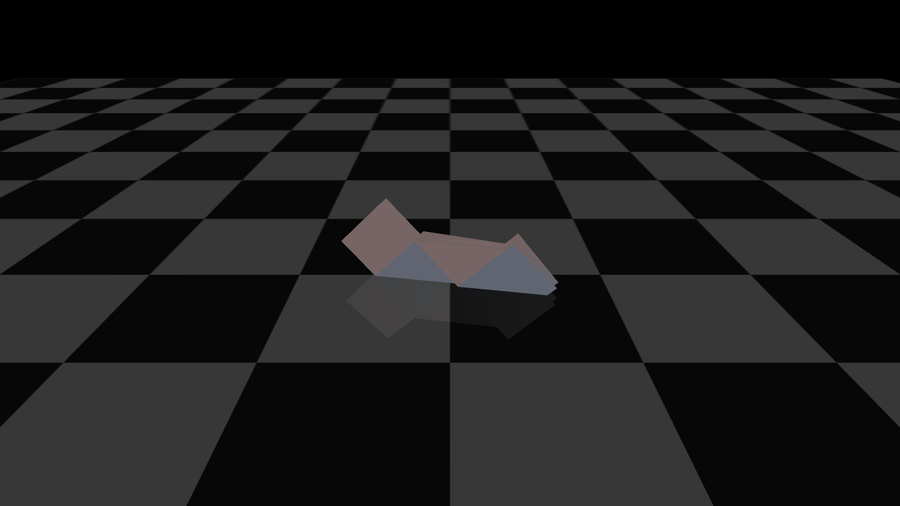

In [ ]:
# ============================================================
# CELL 8k — Final-state snapshot
# ============================================================
mujoco.mj_resetData(m_vid, d_vid)
while d_vid.time < T_TOTAL:
    t = min(d_vid.time / T_FOLD, 1.0); s = t*t*(3-2*t)
    d_vid.ctrl[:] = s * tgt_v
    pin_table(m_vid, d_vid)
    mujoco.mj_step(m_vid, d_vid)

cam_v.azimuth, cam_v.elevation, cam_v.distance = 90, -25, 2.5
renderer.update_scene(d_vid, camera=cam_v)
media.show_image(renderer.render(), width=900)

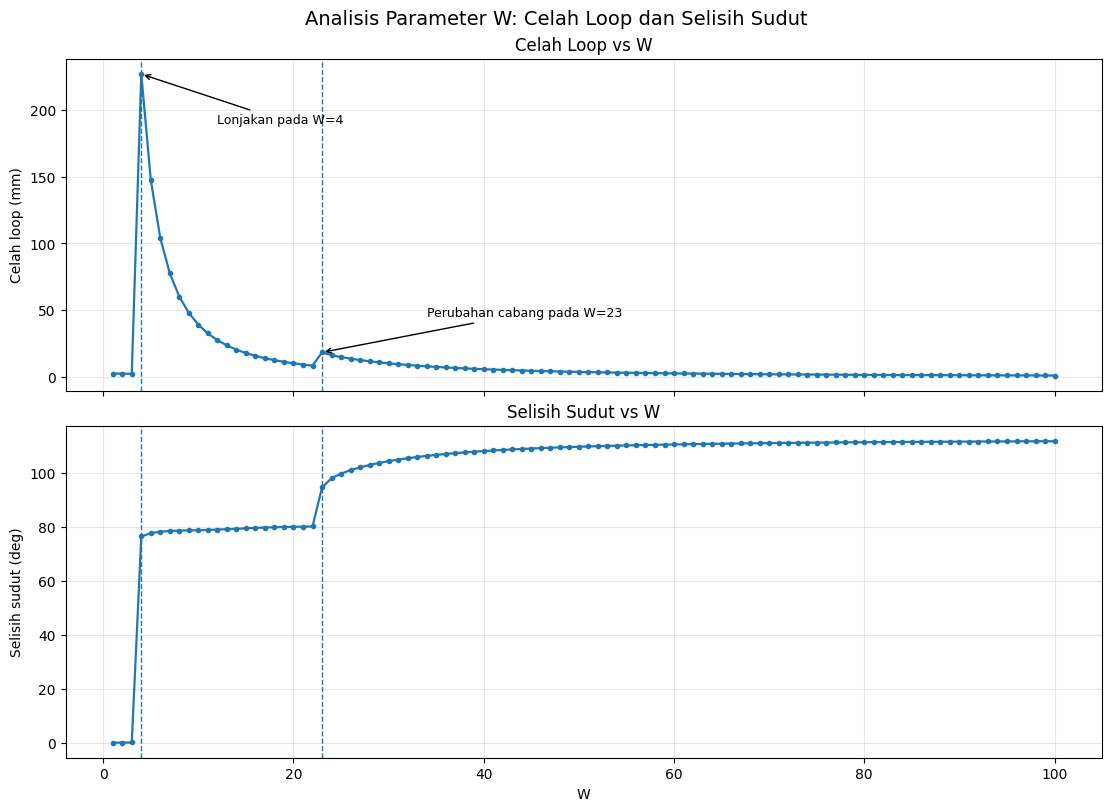

Gambar tersimpan: /content/plot_w_celah_loop_selisih_sudut.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

data = """1 2.363 0.01
2 2.309 0.03
3 2.224 0.07
4 227.158 76.35
5 147.579 77.59
6 104.124 78.13
7 77.556 78.40
8 60.056 78.54
9 47.890 78.63
10 39.083 78.68
11 32.499 78.76
12 27.447 78.93
13 23.485 79.05
14 20.321 79.20
15 17.754 79.38
16 15.643 79.53
17 13.887 79.66
18 12.409 79.77
19 11.156 79.86
20 10.082 79.93
21 9.156 80.00
22 8.351 80.06
23 18.285 94.53
24 16.175 97.93
25 14.736 99.64
26 13.537 100.92
27 12.502 101.96
28 11.593 102.83
29 10.785 103.59
30 10.065 104.24
31 9.415 104.81
32 8.830 105.32
33 8.297 105.78
34 7.813 106.19
35 7.371 106.56
36 6.965 106.90
37 6.592 107.21
38 6.249 107.49
39 5.932 107.75
40 5.639 107.98
41 5.367 108.20
42 5.114 108.40
43 4.879 108.59
44 4.659 108.76
45 4.455 108.93
46 4.263 109.08
47 4.084 109.22
48 3.916 109.35
49 3.757 109.47
50 3.609 109.59
51 3.469 109.69
52 3.337 109.80
53 3.212 109.89
54 3.094 109.98
55 2.983 110.07
56 2.878 110.15
57 2.777 110.23
58 2.682 110.30
59 2.592 110.37
60 2.507 110.43
61 2.425 110.50
62 2.348 110.55
63 2.274 110.61
64 2.204 110.66
65 2.136 110.71
66 2.072 110.76
67 2.011 110.81
68 1.952 110.85
69 1.896 110.90
70 1.842 110.94
71 1.791 110.98
72 1.742 111.01
73 1.694 111.05
74 1.649 111.08
75 1.605 111.11
76 1.563 111.15
77 1.523 111.18
78 1.484 111.21
79 1.447 111.23
80 1.411 111.26
81 1.376 111.29
82 1.343 111.31
83 1.311 111.33
84 1.280 111.36
85 1.250 111.38
86 1.221 111.40
87 1.193 111.42
88 1.166 111.44
89 1.140 111.46
90 1.115 111.48
91 1.091 111.50
92 1.067 111.52
93 1.044 111.53
94 1.022 111.55
95 1.001 111.57
96 0.980 111.58
97 0.960 111.60
98 0.941 111.61
99 0.922 111.62
100 0.903 111.64"""

arr = np.array([[float(v) for v in line.split()] for line in data.splitlines()])
W, gap, angle = arr.T

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True, constrained_layout=True)

axes[0].plot(W, gap, marker='o', markersize=3, linewidth=1.6)
axes[0].set_ylabel('Celah loop (mm)')
axes[0].set_title('Celah Loop vs W')
axes[0].grid(True, alpha=0.3)
axes[0].axvline(4, linestyle='--', linewidth=1)
axes[0].axvline(23, linestyle='--', linewidth=1)
axes[0].annotate('Lonjakan pada W=4', xy=(4, 227.158), xytext=(12, 190),
                 arrowprops=dict(arrowstyle='->'), fontsize=9)
axes[0].annotate('Perubahan cabang pada W=23', xy=(23, 18.285), xytext=(34, 45),
                 arrowprops=dict(arrowstyle='->'), fontsize=9)

axes[1].plot(W, angle, marker='o', markersize=3, linewidth=1.6)
axes[1].set_xlabel('W')
axes[1].set_ylabel('Selisih sudut (deg)')
axes[1].set_title('Selisih Sudut vs W')
axes[1].grid(True, alpha=0.3)
axes[1].axvline(4, linestyle='--', linewidth=1)
axes[1].axvline(23, linestyle='--', linewidth=1)

fig.suptitle('Analisis Parameter W: Celah Loop dan Selisih Sudut', fontsize=14)
# Mengubah path penyimpanan ke folder '/content' Colab yang valid
path = '/content/plot_w_celah_loop_selisih_sudut.png'
fig.savefig(path, dpi=200, bbox_inches='tight')
plt.show()
print(f'Gambar tersimpan: {path}')

In [ ]:
# @title Parameterisasi Sapuan W_CLOSE
W_START = 3 # @param {type:"number"}
W_END = 4 # @param {type:"number"}
W_STEP = 0.01 # @param {type:"number"}

# Ensure we use variables from the Miura-ori model
model_active = model_fold
hinge_adr_active = hinge_adr
target_angles_active = target_angles
_d_active = mujoco.MjData(model_active)

def closure_residual_local(q_h):
    mujoco.mj_resetData(model_active, _d_active)
    _d_active.qpos[hinge_adr_active] = q_h
    mujoco.mj_kinematics(model_active, _d_active)

    res = []
    for k in range(model_active.neq):
        b1 = model_active.eq_obj1id[k]
        b2 = model_active.eq_obj2id[k]
        a1 = model_active.eq_data[k, 0:3]
        a2 = model_active.eq_data[k, 3:6]

        p1 = (
            _d_active.xpos[b1]
            + _d_active.xmat[b1].reshape(3, 3) @ a1
        )
        p2 = (
            _d_active.xpos[b2]
            + _d_active.xmat[b2].reshape(3, 3) @ a2
        )
        res.extend(p1 - p2)

    return np.array(res)


def project(W, n_stage=20, scale=1.0):
    sg = np.linspace(0, 1, n_stage + 1)
    q_prev = np.zeros(len(hinge_adr_active))

    for s in sg:
        des = s * scale * target_angles_active
        sol = least_squares(
            lambda q: np.concatenate([
                W * closure_residual_local(q),
                q - des
            ]),
            q_prev
        )
        q_prev = sol.x

    res = closure_residual_local(q_prev)
    gap = np.abs(res).max() if len(res) > 0 else 0.0
    ang = np.rad2deg(
        np.mean(np.abs(q_prev - scale * target_angles_active))
    )
    return gap, ang


# Generate W values with a constant increment
if W_STEP <= 0:
    raise ValueError("W_STEP harus lebih besar dari 0.")

if W_END < W_START:
    raise ValueError("W_END harus >= W_START.")

W_values = np.arange(
    W_START,
    W_END + W_STEP * 1e-9,
    W_STEP
)

print(f"{'W':>10} {'celah loop (mm)':>16} {'selisih sudut (deg)':>20}")
for W in W_values:
    gap, ang = project(W)
    print(f"{W:10.3e} {gap*1e3:16.3f} {ang:20.2f}")


         W  celah loop (mm)  selisih sudut (deg)
 3.000e+00            0.000                 0.00
 3.010e+00            0.000                 0.00
 3.020e+00            0.000                 0.00
 3.030e+00            0.000                 0.00
 3.040e+00            0.000                 0.00
 3.050e+00            0.000                 0.00
 3.060e+00            0.000                 0.00
 3.070e+00            0.000                 0.00
 3.080e+00            0.000                 0.00
 3.090e+00            0.000                 0.00
 3.100e+00            0.000                 0.00
 3.110e+00            0.000                 0.00
 3.120e+00            0.000                 0.00
 3.130e+00            0.000                 0.00
 3.140e+00            0.000                 0.00
 3.150e+00            0.000                 0.00
 3.160e+00            0.000                 0.00
 3.170e+00            0.000                 0.00
 3.180e+00            0.000                 0.00
 3.190e+00          

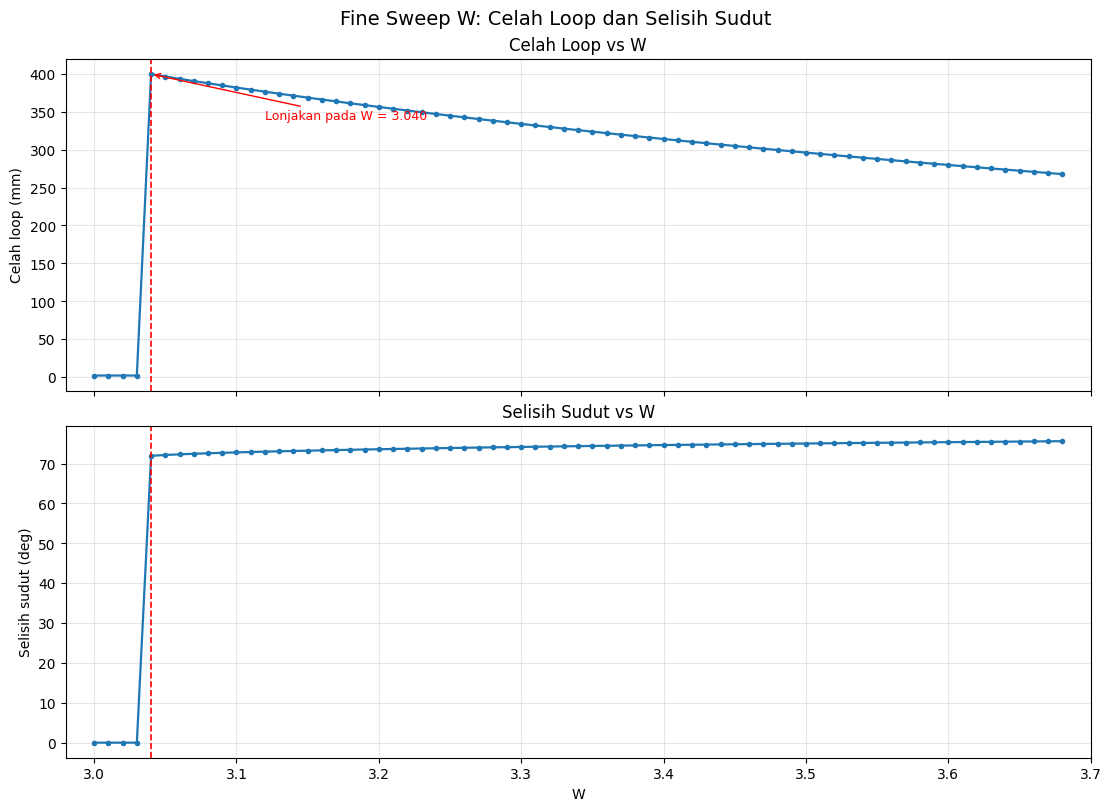

Gambar tersimpan: /content/plot_w_fine_sweep.png
Lonjakan celah loop pertama terdeteksi pada W = 3.040


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

data = """
3.000e+00 2.224 0.07
3.010e+00 2.223 0.07
3.020e+00 2.222 0.07
3.030e+00 2.221 0.07
3.040e+00 399.540 71.93
3.050e+00 396.332 72.15
3.060e+00 393.268 72.31
3.070e+00 390.290 72.45
3.080e+00 387.390 72.57
3.090e+00 384.549 72.69
3.100e+00 381.760 72.79
3.110e+00 379.027 72.89
3.120e+00 376.338 72.98
3.130e+00 373.693 73.07
3.140e+00 371.088 73.15
3.150e+00 368.522 73.23
3.160e+00 365.992 73.30
3.170e+00 363.497 73.38
3.180e+00 361.036 73.45
3.190e+00 358.617 73.52
3.200e+00 356.220 73.59
3.210e+00 353.865 73.65
3.220e+00 351.528 73.71
3.230e+00 349.232 73.77
3.240e+00 346.952 73.83
3.250e+00 344.712 73.89
3.260e+00 342.485 73.95
3.270e+00 340.299 74.00
3.280e+00 338.137 74.06
3.290e+00 335.986 74.11
3.300e+00 333.875 74.16
3.310e+00 331.787 74.21
3.320e+00 329.723 74.26
3.330e+00 327.666 74.31
3.340e+00 325.647 74.36
3.350e+00 323.650 74.41
3.360e+00 321.674 74.45
3.370e+00 319.719 74.50
3.380e+00 317.784 74.54
3.390e+00 315.868 74.59
3.400e+00 313.973 74.63
3.410e+00 312.097 74.67
3.420e+00 310.239 74.71
3.430e+00 308.401 74.75
3.440e+00 306.581 74.79
3.450e+00 304.779 74.83
3.460e+00 302.995 74.87
3.470e+00 301.228 74.91
3.480e+00 299.479 74.95
3.490e+00 297.746 74.98
3.500e+00 296.030 75.02
3.510e+00 294.331 75.06
3.520e+00 292.648 75.09
3.530e+00 290.981 75.13
3.540e+00 289.329 75.16
3.550e+00 287.693 75.20
3.560e+00 286.073 75.23
3.570e+00 284.467 75.26
3.580e+00 282.876 75.29
3.590e+00 281.300 75.33
3.600e+00 279.738 75.36
3.610e+00 278.191 75.39
3.620e+00 276.657 75.42
3.630e+00 275.137 75.45
3.640e+00 273.631 75.48
3.650e+00 272.138 75.51
3.660e+00 270.659 75.54
3.670e+00 269.193 75.57
3.680e+00 267.740 75.60
"""

# Parsing data
parsed_data = [
    [float(v) for v in line.split()]
    for line in data.splitlines()
    if len(line.split()) == 3
]

arr = np.array(parsed_data)
W, gap, angle = arr.T

# Deteksi lonjakan pertama berdasarkan perubahan celah loop
jump_idx = np.argmax(np.abs(np.diff(gap))) + 1
W_jump = W[jump_idx]

# Plot
fig, axes = plt.subplots(
    2, 1,
    figsize=(11, 8),
    sharex=True,
    constrained_layout=True
)

# Celah loop
axes[0].plot(W, gap, marker='o', markersize=3, linewidth=1.6)
axes[0].set_ylabel('Celah loop (mm)')
axes[0].set_title('Celah Loop vs W')
axes[0].grid(True, alpha=0.3)
axes[0].axvline(W_jump, color='red', linestyle='--', linewidth=1.2)

axes[0].annotate(
    f'Lonjakan pada W = {W_jump:.3f}',
    xy=(W_jump, gap[jump_idx]),
    xytext=(W_jump + 0.08, gap[jump_idx] - 60),
    arrowprops=dict(arrowstyle='->', color='red'),
    fontsize=9,
    color='red'
)

# Selisih sudut
axes[1].plot(W, angle, marker='o', markersize=3, linewidth=1.6)
axes[1].set_xlabel('W')
axes[1].set_ylabel('Selisih sudut (deg)')
axes[1].set_title('Selisih Sudut vs W')
axes[1].grid(True, alpha=0.3)
axes[1].axvline(W_jump, color='red', linestyle='--', linewidth=1.2)

# Rentang sumbu x sesuai data
axes[1].set_xlim(W.min() - 0.02, W.max() + 0.02)

fig.suptitle(
    'Fine Sweep W: Celah Loop dan Selisih Sudut',
    fontsize=14
)

# Simpan ke folder Colab
path = '/content/plot_w_fine_sweep.png'
fig.savefig(path, dpi=200, bbox_inches='tight')
plt.show()

print(f'Gambar tersimpan: {path}')
print(f'Lonjakan celah loop pertama terdeteksi pada W = {W_jump:.3f}')



In [ ]:
# @title Parameterisasi Sapuan W_CLOSE
W_START = 3.030e+00 # @param {type:"number"}
W_END = 3.040e+00 # @param {type:"number"}
W_STEP = 0.001 # @param {type:"number"}

# Ensure we use variables from the Miura-ori model
model_active = model_fold
hinge_adr_active = hinge_adr
target_angles_active = target_angles
_d_active = mujoco.MjData(model_active)

def closure_residual_local(q_h):
    mujoco.mj_resetData(model_active, _d_active)
    _d_active.qpos[hinge_adr_active] = q_h
    mujoco.mj_kinematics(model_active, _d_active)

    res = []
    for k in range(model_active.neq):
        b1 = model_active.eq_obj1id[k]
        b2 = model_active.eq_obj2id[k]
        a1 = model_active.eq_data[k, 0:3]
        a2 = model_active.eq_data[k, 3:6]

        p1 = (
            _d_active.xpos[b1]
            + _d_active.xmat[b1].reshape(3, 3) @ a1
        )
        p2 = (
            _d_active.xpos[b2]
            + _d_active.xmat[b2].reshape(3, 3) @ a2
        )
        res.extend(p1 - p2)

    return np.array(res)


def project(W, n_stage=20, scale=1.0):
    sg = np.linspace(0, 1, n_stage + 1)
    q_prev = np.zeros(len(hinge_adr_active))

    for s in sg:
        des = s * scale * target_angles_active
        sol = least_squares(
            lambda q: np.concatenate([
                W * closure_residual_local(q),
                q - des
            ]),
            q_prev
        )
        q_prev = sol.x

    res = closure_residual_local(q_prev)
    gap = np.abs(res).max() if len(res) > 0 else 0.0
    ang = np.rad2deg(
        np.mean(np.abs(q_prev - scale * target_angles_active))
    )
    return gap, ang


# Generate W values with a constant increment
if W_STEP <= 0:
    raise ValueError("W_STEP harus lebih besar dari 0.")

if W_END < W_START:
    raise ValueError("W_END harus >= W_START.")

W_values = np.arange(
    W_START,
    W_END + W_STEP * 1e-9,
    W_STEP
)

print(f"{'W':>10} {'celah loop (mm)':>16} {'selisih sudut (deg)':>20}")
for W in W_values:
    gap, ang = project(W)
    print(f"{W:10.3e} {gap*1e3:16.3f} {ang:20.2f}")


         W  celah loop (mm)  selisih sudut (deg)
 3.030e+00            0.000                 0.00
 3.031e+00            0.000                 0.00
 3.032e+00            0.000                 0.00
 3.033e+00            0.000                 0.00
 3.034e+00            0.000                 0.00
 3.035e+00            0.000                 0.00
 3.036e+00            0.000                 0.00
 3.037e+00            0.000                 0.00
 3.038e+00            0.000                 0.00
 3.039e+00            0.000                 0.00
 3.040e+00            0.000                 0.00


In [ ]:
# @title Parameterisasi Sapuan W_CLOSE
W_START = 3.031e+00 # @param {type:"number"}
W_END = 3.032e+00 # @param {type:"number"}
W_STEP = 0.0001 # @param {type:"number"}

# Ensure we use variables from the Miura-ori model
model_active = model_fold
hinge_adr_active = hinge_adr
target_angles_active = target_angles
_d_active = mujoco.MjData(model_active)

def closure_residual_local(q_h):
    mujoco.mj_resetData(model_active, _d_active)
    _d_active.qpos[hinge_adr_active] = q_h
    mujoco.mj_kinematics(model_active, _d_active)

    res = []
    for k in range(model_active.neq):
        b1 = model_active.eq_obj1id[k]
        b2 = model_active.eq_obj2id[k]
        a1 = model_active.eq_data[k, 0:3]
        a2 = model_active.eq_data[k, 3:6]

        p1 = (
            _d_active.xpos[b1]
            + _d_active.xmat[b1].reshape(3, 3) @ a1
        )
        p2 = (
            _d_active.xpos[b2]
            + _d_active.xmat[b2].reshape(3, 3) @ a2
        )
        res.extend(p1 - p2)

    return np.array(res)


def project(W, n_stage=20, scale=1.0):
    sg = np.linspace(0, 1, n_stage + 1)
    q_prev = np.zeros(len(hinge_adr_active))

    for s in sg:
        des = s * scale * target_angles_active
        sol = least_squares(
            lambda q: np.concatenate([
                W * closure_residual_local(q),
                q - des
            ]),
            q_prev
        )
        q_prev = sol.x

    res = closure_residual_local(q_prev)
    gap = np.abs(res).max() if len(res) > 0 else 0.0
    ang = np.rad2deg(
        np.mean(np.abs(q_prev - scale * target_angles_active))
    )
    return gap, ang


# Generate W values with a constant increment
if W_STEP <= 0:
    raise ValueError("W_STEP harus lebih besar dari 0.")

if W_END < W_START:
    raise ValueError("W_END harus >= W_START.")

W_values = np.arange(
    W_START,
    W_END + W_STEP * 1e-9,
    W_STEP
)

print(f"{'W':>10} {'celah loop (mm)':>16} {'selisih sudut (deg)':>20}")
for W in W_values:
    gap, ang = project(W)
    print(f"{W:10.3e} {gap*1e3:16.3f} {ang:20.2f}")


         W  celah loop (mm)  selisih sudut (deg)
 3.031e+00            0.000                 0.00
 3.031e+00            0.000                 0.00
 3.031e+00            0.000                 0.00
 3.031e+00            0.000                 0.00
 3.031e+00            0.000                 0.00
 3.032e+00            0.000                 0.00
 3.032e+00            0.000                 0.00
 3.032e+00            0.000                 0.00
 3.032e+00            0.000                 0.00
 3.032e+00            0.000                 0.00
 3.032e+00            0.000                 0.00


In [ ]:
# ============================================================
# CELL 8c — Proyeksi sudut ke lintasan lipat yang loop-nya tertutup
# ============================================================

from scipy.optimize import least_squares

mujoco.mj_resetData(model_fold, data_fold)
_d = mujoco.MjData(model_fold)          # data khusus untuk kinematika

def closure_residual(q_h):
    mujoco.mj_resetData(model_fold, _d)
    _d.qpos[hinge_adr] = q_h
    mujoco.mj_kinematics(model_fold, _d)
    res = []
    for k in range(model_fold.neq):
        b1, b2 = model_fold.eq_obj1id[k], model_fold.eq_obj2id[k]
        a1 = model_fold.eq_data[k, 0:3]
        a2 = model_fold.eq_data[k, 3:6]
        p1 = _d.xpos[b1] + _d.xmat[b1].reshape(3, 3) @ a1
        p2 = _d.xpos[b2] + _d.xmat[b2].reshape(3, 3) @ a2
        res.extend(p1 - p2)
    return np.array(res)

N_STAGE  = 60
W_CLOSE  = 3.031e+00                           # makin besar = penutupan loop makin diutamakan
s_grid   = np.linspace(0, 1, N_STAGE + 1)
path     = np.zeros((N_STAGE + 1, len(hinge_adr)))
close_err = np.zeros(N_STAGE + 1)

q_prev = np.zeros(len(hinge_adr))
for n, s in enumerate(s_grid):
    desired = s * target_angles
    f = lambda q: np.concatenate([W_CLOSE * closure_residual(q), q - desired])
    sol = least_squares(f, q_prev)       # mulai dari solusi sebelumnya -> tetap di cabang yang sama
    path[n]      = sol.x
    close_err[n] = np.abs(closure_residual(sol.x)).max() if model_fold.neq else 0.0
    q_prev       = sol.x

print("Sudut target (deg)   :", np.round(np.rad2deg(target_angles), 1))
print("Sudut yang tercapai  :", np.round(np.rad2deg(path[-1]), 1))
print("Sisa loop terburuk (m):", float(close_err.max()))
print("Selisih rata-rata dari target (deg):",
      round(float(np.rad2deg(np.mean(np.abs(path[-1] - target_angles)))), 2))

Sudut target (deg)   : [ 176.4 -176.4  176.4 -176.4  176.4 -176.4 -176.4 -176.4  176.4 -176.4
 -176.4  176.4 -176.4 -176.4  176.4]
Sudut yang tercapai  : [ 177.8 -177.   177.8 -179.3  178.7 -178.3 -180.3 -179.9  179.2 -180.3
 -179.9  179.2 -179.3 -178.7  178.3]
Sisa loop terburuk (m): 0.3752330995747917
Selisih rata-rata dari target (deg): 2.52


In [ ]:
# ============================================================
# CELL 8d — Simulasi memakai lintasan yang konsisten
# ============================================================

T_FOLD, T_TOTAL, FPS = 4.0, 8.0, 30

def ctrl_at(time):
    t = min(time / T_FOLD, 1.0)
    s = t * t * (3 - 2 * t)
    return np.array([np.interp(s, s_grid, path[:, h]) for h in range(path.shape[1])])

mujoco.mj_resetData(model_fold, data_fold)
frames, worst = [], 0.0

while data_fold.time < T_TOTAL:
    data_fold.ctrl[:] = ctrl_at(data_fold.time)
    drive_table(model_fold, data_fold, data_fold.time)
    mujoco.mj_step(model_fold, data_fold)

    eq = data_fold.efc_type == mujoco.mjtConstraint.mjCNSTR_EQUALITY
    if eq.any():
        worst = max(worst, float(np.abs(data_fold.efc_pos[eq]).max()))

    if len(frames) < data_fold.time * FPS:
        renderer.update_scene(data_fold, camera=cam)
        frames.append(renderer.render())

media.show_video(frames, fps=FPS)
print("Violation terburuk (m):", round(worst, 5))
print("Sudut aktual (deg):", np.round(np.rad2deg(data_fold.qpos[hinge_adr]), 2))

This browser does not support the video tag.


Violation terburuk (m): 0.03416
Sudut aktual (deg): [ 177.58 -175.9   177.33   -1.01  179.95 -176.36   -3.31 -179.56  179.31
    3.49 -179.6   179.36   -7.8  -179.95  176.38]


In [ ]:
# ============================================================
# CELL D1 — Diagnose: why doesn't it reach the target?
# ============================================================

def test_fold(contacts=True, gravity=True, steps=3000):
    mujoco.mj_resetData(model_fold, data_fold)
    if contacts:
        model_fold.opt.disableflags &= ~int(mujoco.mjtDisableBit.mjDSBL_CONTACT.value)
    else:
        model_fold.opt.disableflags |= int(mujoco.mjtDisableBit.mjDSBL_CONTACT.value)
    model_fold.opt.gravity[:] = [0, 0, -9.81 if gravity else 0]

    data_fold.ctrl[:] = target_angles
    for _ in range(steps):
        mujoco.mj_step(model_fold, data_fold)

    eq = data_fold.efc_type == mujoco.mjtConstraint.mjCNSTR_EQUALITY
    print(f"contacts={contacts}, gravity={gravity}")
    for h, a, t in zip(info["hinges"], data_fold.qpos[hinge_adr], target_angles):
        print(f"  {h['name']}: target {np.rad2deg(t):7.1f}   actual {np.rad2deg(a):7.1f}")
    print("  loop edges:", info["n_loops"],
          "| max loop violation:",
          round(float(np.abs(data_fold.efc_pos[eq]).max()), 4) if eq.any() else 0.0)

test_fold(contacts=True,  gravity=True)    # your normal setup
test_fold(contacts=False, gravity=False)   # nothing in the way

contacts=True, gravity=True
  crease_0: target   -90.0   actual   -51.3
  crease_1: target   -90.0   actual   -40.2
  crease_2: target   -90.0   actual   -38.8
  crease_3: target   -90.0   actual   -47.4
  crease_4: target   -90.0   actual   -62.6
  loop edges: 0 | max loop violation: 0.0
contacts=False, gravity=False
  crease_0: target   -90.0   actual   -90.0
  crease_1: target   -90.0   actual   -90.0
  crease_2: target   -90.0   actual   -90.0
  crease_3: target   -90.0   actual   -90.0
  crease_4: target   -90.0   actual   -90.0
  loop edges: 0 | max loop violation: 0.0


In [ ]:
# ============================================================
# CELL D2 — Diagnose: what is holding the hinge back?
# ============================================================

# rebuild fresh from the current XML (rules out a stale model_fold / hinge_adr)
m = mujoco.MjModel.from_xml_string(xml_fold)
d = mujoco.MjData(m)
m.opt.disableflags |= mujoco.mjtDisableBit.mjDSBL_CONTACT
m.opt.gravity[:] = 0

j = m.joint("crease_0")
print("joint range (deg)  :", np.rad2deg(j.range))
print("joint limited      :", j.limited)
print("joint damping/arm. :", m.dof_damping[j.dofadr[0]], m.dof_armature[j.dofadr[0]])
print("actuator kp        :", m.actuator_gainprm[0, :3])
print("actuator forcerange:", m.actuator_forcerange[0], "limited:", m.actuator_forcelimited[0])
print("actuator ctrlrange :", m.actuator_ctrlrange[0], "limited:", m.actuator_ctrllimited[0])
print("body masses        :", np.round(m.body_mass[1:], 4))
print("dof inertia (diag) :", np.round(m.dof_M0[:], 5))

d.ctrl[:] = target_angles
qadr = j.qposadr[0]
print("\n time   ctrl    angle   act.force")
for step in range(3000):
    mujoco.mj_step(m, d)
    if step % 250 == 0:
        print(f"{d.time:5.2f}  {np.rad2deg(d.ctrl[0]):6.1f}  "
              f"{np.rad2deg(d.qpos[qadr]):6.2f}  {d.actuator_force[0]:8.3f}")

joint range (deg)  : [-180.00042092  180.00042092]
joint limited      : [1]
joint damping/arm. : 0.003 0.001
actuator kp        : [2. 0. 0.]
actuator forcerange: [-2.  2.] limited: True
actuator ctrlrange : [-3.1416  3.1416] limited: True
body masses        : [1.0e+03 3.6e-02 2.8e-02 3.6e-02 3.6e-02 2.8e-02 3.6e-02]
dof inertia (diag) : [1.000e+03 1.000e+03 2.000e-01 2.000e-01 2.000e-01 3.467e-02 3.467e-02
 6.933e-02 1.650e-01 1.650e-01 3.259e-02 1.370e-01 1.370e-01 1.825e-02
 1.010e-01 1.010e-01 9.330e-03 6.500e-02 6.500e-02 4.410e-03 3.700e-02
 3.700e-02 2.080e-03]

 time   ctrl    angle   act.force
 0.00   -90.0   -0.05    -2.000
 0.25   -90.0  -89.04     0.028
 0.50   -90.0  -89.96     0.000
 0.75   -90.0  -90.00     0.000
 1.00   -90.0  -90.00     0.000
 1.25   -90.0  -90.00     0.000
 1.50   -90.0  -90.00    -0.000
 1.75   -90.0  -90.00    -0.000
 2.00   -90.0  -90.00    -0.000
 2.25   -90.0  -90.00    -0.000
 2.50   -90.0  -90.00    -0.000
 2.75   -90.0  -90.00    -0.000


In [ ]:
# ============================================================
# CELL D3 — Ukur "sobek" per loop edge dan jarak engsel
# ============================================================

mujoco.mj_resetData(model_fold, data_fold)
model_fold.opt.disableflags &= ~int(mujoco.mjtDisableBit.mjDSBL_CONTACT.value)
model_fold.opt.gravity[:] = [0, 0, -9.81]

worst = 0.0
for step in range(4000):
    t = min(data_fold.time / 2.0, 1.0)
    s = t * t * (3 - 2 * t)
    data_fold.ctrl[:] = s * target_angles
    drive_table(model_fold, data_fold, data_fold.time)
    mujoco.mj_step(model_fold, data_fold)

    eq = data_fold.efc_type == mujoco.mjtConstraint.mjCNSTR_EQUALITY
    v = float(np.abs(data_fold.efc_pos[eq]).max()) if eq.any() else 0.0
    worst = max(worst, v)
    if step % 500 == 0:
        print(f"t={data_fold.time:4.2f}  loop violation={v:.5f} m  "
              f"act.force max={np.abs(data_fold.actuator_force).max():.1f}")

print("Violation terburuk (m):", round(worst, 5))

t=0.00  loop violation=0.00000 m  act.force max=0.0
t=0.50  loop violation=0.00000 m  act.force max=0.5
t=1.00  loop violation=0.00000 m  act.force max=0.2
t=1.50  loop violation=0.00000 m  act.force max=1.3
t=2.00  loop violation=0.00000 m  act.force max=1.7
t=2.50  loop violation=0.00000 m  act.force max=2.0
t=3.00  loop violation=0.00000 m  act.force max=1.8
t=3.50  loop violation=0.00000 m  act.force max=1.9
Violation terburuk (m): 0.0


In [ ]:
# ============================================================
# CELL 9 — Fitness function for the genetic algorithm
# ============================================================

from shapely.geometry import MultiPoint

def evaluate(genome, T_FOLD=2.0, T_TOTAL=4.0, vibrate=True):
    """genome -> dict with 'fitness' (higher is better). Edit the score at the bottom."""
    try:
        creases = decode_genome(genome)
        pat = build_pattern(creases)
        if not pat.valid:
            return dict(fitness=-1e3, reason=pat.reason)
        xml, inf = generate_xml(pat, creases)
        m = mujoco.MjModel.from_xml_string(xml)
    except Exception as ex:
        return dict(fitness=-1e3, reason=f"build error: {str(ex)[:80]}")

    d = mujoco.MjData(m)
    h_adr = np.array([m.joint(h["name"]).qposadr[0] for h in inf["hinges"]], dtype=int)

    while d.time < T_TOTAL:
        t = min(d.time / T_FOLD, 1.0)
        s = t * t * (3 - 2 * t)
        d.ctrl[:] = s * inf["targets"]
        if vibrate:
            drive_table(m, d, d.time)
        mujoco.mj_step(m, d)

    if not np.isfinite(d.qpos).all():
        return dict(fitness=-1e3, reason="unstable simulation")

    # how badly the closed-loop constraints are violated (0 = rigidly foldable)
    eq = d.efc_type == mujoco.mjtConstraint.mjCNSTR_EQUALITY
    violation = float(np.abs(d.efc_pos[eq]).max()) if eq.any() else 0.0

    # how far the actuated hinges are from their targets
    reach_err = float(np.mean(np.abs(d.qpos[h_adr] - inf["targets"]))) if len(h_adr) else 0.0

    # footprint of the folded paper (convex hull of all face-triangle centres, xy)
    table_id = m.body("table").id
    ids = [g for g in range(m.ngeom) if m.geom_bodyid[g] != table_id]
    footprint = MultiPoint(d.geom_xpos[ids, :2]).convex_hull.area

    # ---- placeholder score: fold small, keep constraints satisfied ----
    fitness = -footprint - 5.0 * violation - 1.0 * reach_err

    return dict(fitness=fitness, footprint=footprint, violation=violation,
                reach_err=reach_err, n_faces=inf["n_faces"], n_loops=inf["n_loops"],
                n_creases=len(creases))


print(evaluate(genome))

{'fitness': -1.5830742114767968, 'footprint': 0.2872117193939116, 'violation': 0.04726663928521796, 'reach_err': 1.0595292956567954, 'n_faces': 10, 'n_loops': 5, 'n_creases': 4}
